### Data Ingestion

In [1]:
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [86]:
import os, shutil, datetime as dt
import requests
from io import StringIO

SNAP   = "data/sp500_constituents_snapshot.csv"
LEGACY = "sp500_constituents_2026-11-21.csv"             # the file saved on 21 Nov 2026
os.makedirs("data", exist_ok=True)

if not os.path.exists(SNAP) and os.path.exists(LEGACY):  # one-off: move the original file into data/
    shutil.copy(LEGACY, SNAP)

if os.path.exists(SNAP):                                 # every rerun (and the examiner's): load, never download
    sp500_df = pd.read_csv(SNAP)
    retrieval_ts = pd.Timestamp(sp500_df["Retrieved_On"].iloc[0]).to_pydatetime()
    source = "saved snapshot (not re-downloaded)"
else:                                                    # only if no snapshot exists at all
    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    retrieval_ts = dt.datetime.now()
    resp = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    resp.raise_for_status()
    sp500_df = pd.read_html(StringIO(resp.text))[0]
    sp500_df["Retrieved_On"] = retrieval_ts.strftime("%Y-%m-%d %H:%M:%S")
    sp500_df.to_csv(SNAP, index=False)
    source = "live download from Wikipedia"

retrieval_date = retrieval_ts.date().isoformat()
tickers = sp500_df["Symbol"].str.replace(".", "-", regex=False).tolist()    # Yahoo uses "-" (BRK.B -> BRK-B)

print("Source            :", source)
print("Retrieval date    :", retrieval_date)
print("Tickers extracted :", len(tickers))
sp500_df[["Symbol", "Security", "GICS Sector"]].head(10)

Source            : saved snapshot (not re-downloaded)
Retrieval date    : 2026-11-21
Tickers extracted : 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [87]:
start = '2021-01-01'
end   = '2025-01-01'      # end date is exclusive

all_symbols = tickers + ['^GSPC']          # shares + benchmark in one download

raw_df = yf.download(
    all_symbols, start=start, end=end,
    auto_adjust=False,      # keep both Close and Adj Close
    actions=True,           # keep Dividends and Stock Splits 
    progress=False
)


print('Shape      :', raw_df.shape)
print('Columns    :', list(raw_df.columns))
raw_df.head()

$VYLR: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$SNDK: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$HONA: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$FDXF: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")
$Q: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477200, endDate = 1735707600")

5 Failed downloads:
['VYLR', 'SNDK', 'HONA', 'FDXF', 'Q']: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1609477

Shape      : (1005, 4022)
Columns    : [('Adj Close', 'A'), ('Adj Close', 'AAPL'), ('Adj Close', 'ABBV'), ('Adj Close', 'ABNB'), ('Adj Close', 'ABT'), ('Adj Close', 'ACGL'), ('Adj Close', 'ACN'), ('Adj Close', 'ADBE'), ('Adj Close', 'ADI'), ('Adj Close', 'ADM'), ('Adj Close', 'ADP'), ('Adj Close', 'ADSK'), ('Adj Close', 'AEE'), ('Adj Close', 'AEP'), ('Adj Close', 'AES'), ('Adj Close', 'AFL'), ('Adj Close', 'AIG'), ('Adj Close', 'AIZ'), ('Adj Close', 'AJG'), ('Adj Close', 'AKAM'), ('Adj Close', 'ALB'), ('Adj Close', 'ALGN'), ('Adj Close', 'ALL'), ('Adj Close', 'ALLE'), ('Adj Close', 'AMAT'), ('Adj Close', 'AMCR'), ('Adj Close', 'AMD'), ('Adj Close', 'AME'), ('Adj Close', 'AMGN'), ('Adj Close', 'AMP'), ('Adj Close', 'AMT'), ('Adj Close', 'AMZN'), ('Adj Close', 'ANET'), ('Adj Close', 'AON'), ('Adj Close', 'AOS'), ('Adj Close', 'APA'), ('Adj Close', 'APD'), ('Adj Close', 'APH'), ('Adj Close', 'APO'), ('Adj Close', 'APP'), ('Adj Close', 'APTV'), ('Adj Close', 'ARE'), ('Adj Close', 'ARES'), 

Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009125  125.537117  84.219139  139.149994  97.269699   
2021-01-05  114.941246  127.089233  85.090027  148.300003  98.473206   
2021-01-06  118.093224  122.811211  84.354965  142.770004  98.268166   
2021-01-07  121.235596  127.001930  85.257805  151.270004  99.222061   
2021-01-08  122.100464  128.098129  85.705223  149.770004  99.498398   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029358  485.339996  132.622620  42.189476  ...   
2021-01-05  33.319485  233.350281  485.690002  134.993149  43.010098  ...   
2021-01-06  34.783871  235.901596  466.309998  135.601685  44.752838  ...   
2021-01-07  34.460564  238.127304  477.739990  141.332748  44.355217  ...   
2021-01-08  34.650742  238.995895  485.100006  142.359070  44.473656  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 4022 columns]

In [88]:
present = raw_df.columns.get_level_values(1).unique()
df_all = (
    pd.concat(
        {t: raw_df.xs(t, axis=1, level=1) for t in present},
        names=['Ticker', 'Date']
    )
    .reset_index()
    .sort_values(['Ticker', 'Date'])
    .reset_index(drop=True)
)


In [89]:
df_all.head()

Price,Ticker,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,A,2021-01-04,114.009125,118.639999,0.194,120.089996,117.110001,118.940002,0.0,2030700.0
1,A,2021-01-05,114.941246,119.610001,0.000,120.320000,118.070000,118.480003,0.0,2344000.0
2,A,2021-01-06,118.093224,122.889999,0.000,123.879997,118.209999,118.690002,0.0,2428500.0
3,A,2021-01-07,121.235596,126.160004,0.000,127.480003,124.110001,124.330002,0.0,1775900.0
4,A,2021-01-08,122.100464,127.059998,0.000,127.639999,125.849998,126.489998,0.0,1577200.0


In [90]:
import os
df_all.to_csv('df_all_sp500_2021_2025.csv', index=False)
print('Saved to:', os.path.abspath('df_all_sp500_2021_2025.csv'))   # add "import os" at the top if needed

Saved to: c:\Users\basil\Documents\CRM_CW\20230762_CRM\df_all_sp500_2021_2025.csv


### Data Validation & Preprocessing

In [91]:
CACHE_DIR = "cache"; OUT_DIR = "outputs"
os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

In [92]:
dup_rows = df_all.duplicated(subset=['Ticker', 'Date']).sum()
print('1. Duplicate (Ticker, Date) rows:', dup_rows)
if dup_rows:
    print(df_all[df_all.duplicated(subset=['Ticker', 'Date'], keep=False)].head())

1. Duplicate (Ticker, Date) rows: 0


In [93]:
cols = df_all.columns
missing = df_all.groupby('Ticker')[cols].apply(lambda g: g.isna().sum())
print('\n2. Tickers with missing values:', int((missing.sum(axis=1) > 0).sum()))
print(missing[missing.sum(axis=1) > 0].sort_values('Adj Close', ascending=False).head(15))


2. Tickers with missing values: 15
Price   Ticker  Date  Adj Close  Close  Dividends  High   Low  Open  \
Ticker                                                                
FDXF         0     0       1005   1005       1005  1005  1005  1005   
HONA         0     0       1005   1005       1005  1005  1005  1005   
Q            0     0       1005   1005       1005  1005  1005  1005   
SNDK         0     0       1005   1005       1005  1005  1005  1005   
VYLR         0     0       1005   1005       1005  1005  1005  1005   
GEV          0     0        812    812        812   812   812   812   
SOLV         0     0        811    811        811   811   811   811   
RDDT         0     0        808    808        808   808   808   808   
VLTO         0     0        692    692        692   692   692   692   
GEHC         0     0        492    492        492   492   492   492   
CEG          0     0        263    263        263   263   263   263   
HOOD         0     0        143    143   

In [94]:
nonpos = df_all[(df_all['Adj Close'] <= 0) | (df_all['Close'] <= 0)]
print('\n3. Rows with non-positive Adj Close / Close:', len(nonpos))
print(nonpos[['Ticker', 'Date', 'Adj Close', 'Close']].head())


3. Rows with non-positive Adj Close / Close: 0
Empty DataFrame
Columns: [Ticker, Date, Adj Close, Close]
Index: []


In [95]:
vol_neg  = df_all[df_all['Volume'] < 0]
vol_zero = df_all[df_all['Volume'] == 0]
vol_frac = df_all[(df_all['Volume'].notna()) & (df_all['Volume'] % 1 != 0)]
print('\n4. Volume errors -> negative:', len(vol_neg),
      '| zero:', len(vol_zero), '| non-integer:', len(vol_frac))
print('   Tickers with zero-volume days:', vol_zero['Ticker'].nunique())


4. Volume errors -> negative: 0 | zero: 452 | non-integer: 0
   Tickers with zero-volume days: 3


In [96]:
vol_zero

Price,Ticker,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
183918,FERG,2021-01-07,106.624657,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0.0
183919,FERG,2021-01-08,106.624657,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0.0
183921,FERG,2021-01-12,109.173805,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0.0
183922,FERG,2021-01-13,109.173805,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0.0
183923,FERG,2021-01-14,109.173805,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
422968,SW,2024-06-17,41.343594,44.799999,0.0,44.799999,44.799999,44.799999,0.0,0.0
422973,SW,2024-06-25,42.534058,46.090000,0.0,46.090000,46.090000,46.090000,0.0,0.0
422978,SW,2024-07-02,42.543289,46.099998,0.0,46.099998,46.099998,46.099998,0.0,0.0
422980,SW,2024-07-05,41.675808,45.160000,0.0,45.160000,45.160000,45.160000,0.0,0.0


In [97]:
df_all

Price,Ticker,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,A,2021-01-04,114.009125,118.639999,0.194,120.089996,117.110001,118.940002,0.0,2.030700e+06
1,A,2021-01-05,114.941246,119.610001,0.000,120.320000,118.070000,118.480003,0.0,2.344000e+06
2,A,2021-01-06,118.093224,122.889999,0.000,123.879997,118.209999,118.690002,0.0,2.428500e+06
3,A,2021-01-07,121.235596,126.160004,0.000,127.480003,124.110001,124.330002,0.0,1.775900e+06
4,A,2021-01-08,122.100464,127.059998,0.000,127.639999,125.849998,126.489998,0.0,1.577200e+06
...,...,...,...,...,...,...,...,...,...,...
506515,^GSPC,2024-12-24,6040.040039,6040.040039,0.000,6040.100098,5981.439941,5984.629883,0.0,1.757720e+09
506516,^GSPC,2024-12-26,6037.589844,6037.589844,0.000,6049.750000,6007.370117,6024.970215,0.0,2.904530e+09
506517,^GSPC,2024-12-27,5970.839844,5970.839844,0.000,6006.169922,5932.950195,6006.169922,0.0,3.159610e+09
506518,^GSPC,2024-12-30,5906.939941,5906.939941,0.000,5940.790039,5869.160156,5920.669922,0.0,3.433250e+09


In [98]:
BENCH_SYMBOL = '^GSPC'

# DataFrames split from df_all (these must be tables, not strings or lists)
bench  = df_all[df_all['Ticker'] == BENCH_SYMBOL]
shares = df_all[df_all['Ticker'] != BENCH_SYMBOL]

calendar = pd.DatetimeIndex(bench.dropna(subset=['Adj Close'])['Date'].unique()).sort_values()

hist = (shares.dropna(subset=['Adj Close'])
        .groupby('Ticker')['Date']
        .agg(first='min', last='max', n='count'))
hist['expected']     = len(calendar)
hist['missing_days'] = hist['expected'] - hist['n']
hist['late_start']   = hist['first'] > calendar[0]
hist['early_end']    = hist['last']  < calendar[-1]

n_no_data = shares['Ticker'].nunique() - len(hist)

print(f'5. Benchmark trading days: {len(calendar)} ({calendar[0].date()} to {calendar[-1].date()})')
print('   Tickers with a full history  :', int((hist['missing_days'] == 0).sum()))
print('   Tickers with missing days    :', int((hist['missing_days'] > 0).sum()))
print('   Late starts / early ends     :', int(hist['late_start'].sum()), '/', int(hist['early_end'].sum()))
print('   Tickers with NO data at all  :', n_no_data)
hist[hist['missing_days'] > 0].sort_values('missing_days', ascending=False).head(15)

5. Benchmark trading days: 1005 (2021-01-04 to 2024-12-31)
   Tickers with a full history  : 488
   Tickers with missing days    : 10
   Late starts / early ends     : 10 / 0
   Tickers with NO data at all  : 5


,first,last,n,expected,missing_days,late_start,early_end
Ticker,,,,,,,
GEV,2024-03-27,2024-12-31,193,1005,812,True,False
SOLV,2024-03-26,2024-12-31,194,1005,811,True,False
RDDT,2024-03-21,2024-12-31,197,1005,808,True,False
VLTO,2023-10-04,2024-12-31,313,1005,692,True,False
GEHC,2022-12-15,2024-12-31,513,1005,492,True,False
CEG,2022-01-19,2024-12-31,742,1005,263,True,False
HOOD,2021-07-29,2024-12-31,862,1005,143,True,False
APP,2021-04-15,2024-12-31,935,1005,70,True,False
COIN,2021-04-14,2024-12-31,936,1005,69,True,False


In [99]:
# 6. corporate actions (kept, not excluded: Adj Close already accounts for them)
splits = shares[shares["Stock Splits"].fillna(0) > 0][["Ticker", "Date", "Stock Splits"]]
divs   = shares[shares["Dividends"].fillna(0) > 0].groupby("Ticker").size()
print("6. Split events:", len(splits), "across", splits["Ticker"].nunique(), "tickers")
print(splits.sort_values("Date").to_string(index=False))
print("   Tickers paying dividends in the period:", len(divs))

# large one-day Close moves with no recorded split = possible unrecorded action or bad data
s = shares.sort_values(["Ticker", "Date"]).copy()
s["close_ret"] = s["Close"] / s.groupby("Ticker")["Close"].shift(1) - 1
jumps = s[(s["close_ret"].abs() > 0.35) & (s["Stock Splits"].fillna(0) == 0)]
print("   Unexplained >35% one-day Close moves:", len(jumps))
print(jumps[["Ticker", "Date", "close_ret"]].head(10).to_string(index=False))

# splits: Yahoo Close and Volume are split-adjusted consistently, so Close x Volume (Monetary) stays valid

6. Split events: 61 across 53 tickers
Ticker       Date  Stock Splits
   APH 2021-03-05         2.000
   SHW 2021-04-01         3.000
   MRK 2021-06-03         1.048
  CSGP 2021-06-28        10.000
   CSX 2021-06-29         3.000
   DTE 2021-07-01         1.175
  NVDA 2021-07-20         4.000
    GE 2021-08-02         0.125
   RJF 2021-09-22         1.500
    IP 2021-10-01         1.056
  ISRG 2021-10-05         3.000
  MCHP 2021-10-13         2.000
  DELL 2021-11-02         1.973
   IBM 2021-11-04         1.046
     O 2021-11-15         1.032
  ANET 2021-11-18         4.000
   EXC 2022-02-02         1.402
   ZBH 2022-03-01         1.030
   WRB 2022-03-24         1.500
   BDX 2022-04-01         1.025
     T 2022-04-11         1.324
  AMZN 2022-06-06        20.000
  DXCM 2022-06-13         4.000
  FTNT 2022-06-23         5.000
  GOOG 2022-07-18        20.000
 GOOGL 2022-07-18        20.000
  TSLA 2022-08-25         3.000
  NDAQ 2022-08-29         3.000
  PANW 2022-09-14         3.000
  

In [100]:
BENCH_SYMBOL = '^GSPC'
bench  = df_all[df_all['Ticker'] == BENCH_SYMBOL]
shares = df_all[df_all['Ticker'] != BENCH_SYMBOL]

# Rule 1: the benchmark's trading days are the reference calendar
calendar = bench.dropna(subset=['Adj Close'])['Date'].unique()
n_days = len(calendar)

# Count, per ticker, how many days have good data and look for bad values
g = shares.groupby('Ticker')
check = pd.DataFrame({
    'good_days':    g.apply(lambda x: x[['Adj Close', 'Close', 'Volume']].dropna().shape[0]),
    'nonpos_price': g.apply(lambda x: ((x['Adj Close'] <= 0) | (x['Close'] <= 0)).sum()),
    'bad_volume':   g.apply(lambda x: ((x['Volume'] <= 0)).sum()),
})

# Rule 2: write the reason for each ticker that fails
def reason(r):
    why = []
    if r.good_days < n_days:      why.append(f'incomplete history ({r.good_days} of {n_days} days)')
    if r.nonpos_price > 0:        why.append('non-positive price')
    if r.bad_volume > 0:          why.append('zero or negative volume')
    return '; '.join(why)

check['Reason'] = check.apply(reason, axis=1)
check['Status'] = check['Reason'].apply(lambda x: 'Included' if x == '' else 'Excluded')

# Build the clean DataFrame (shares that passed + the benchmark)
keep = check.index[check['Status'] == 'Included'].tolist()
df_clean = df_all[df_all['Ticker'].isin(keep + [BENCH_SYMBOL])].copy()

# Summary for your supervisor
print('Shares downloaded :', len(check))
print('Shares excluded   :', (check['Status'] == 'Excluded').sum())
print('Shares retained   :', len(keep))
print('\nExcluded shares and reasons:')
print(check.loc[check['Status'] == 'Excluded', 'Reason'].to_string())

check.to_csv('inclusion_exclusion_log.csv')
df_clean.to_csv('df_clean.csv', index=False)

Shares downloaded : 503
Shares excluded   : 17
Shares retained   : 486

Excluded shares and reasons:
Ticker
APP     incomplete history (935 of 1005 days)
CEG     incomplete history (742 of 1005 days)
COIN    incomplete history (936 of 1005 days)
EXE     incomplete history (979 of 1005 days)
FDXF      incomplete history (0 of 1005 days)
FERG                  zero or negative volume
GEHC    incomplete history (513 of 1005 days)
GEV     incomplete history (193 of 1005 days)
HONA      incomplete history (0 of 1005 days)
HOOD    incomplete history (862 of 1005 days)
Q         incomplete history (0 of 1005 days)
RDDT    incomplete history (197 of 1005 days)
SNDK      incomplete history (0 of 1005 days)
SOLV    incomplete history (194 of 1005 days)
SW                    zero or negative volume
VLTO    incomplete history (313 of 1005 days)
VYLR      incomplete history (0 of 1005 days)


Dividends column present   : True
Dividends non-missing rows : 497309 | rows > 0: 6086
Dividend events: 6024 | payers: 392 | total per share: $4,083.92 | split events: 61


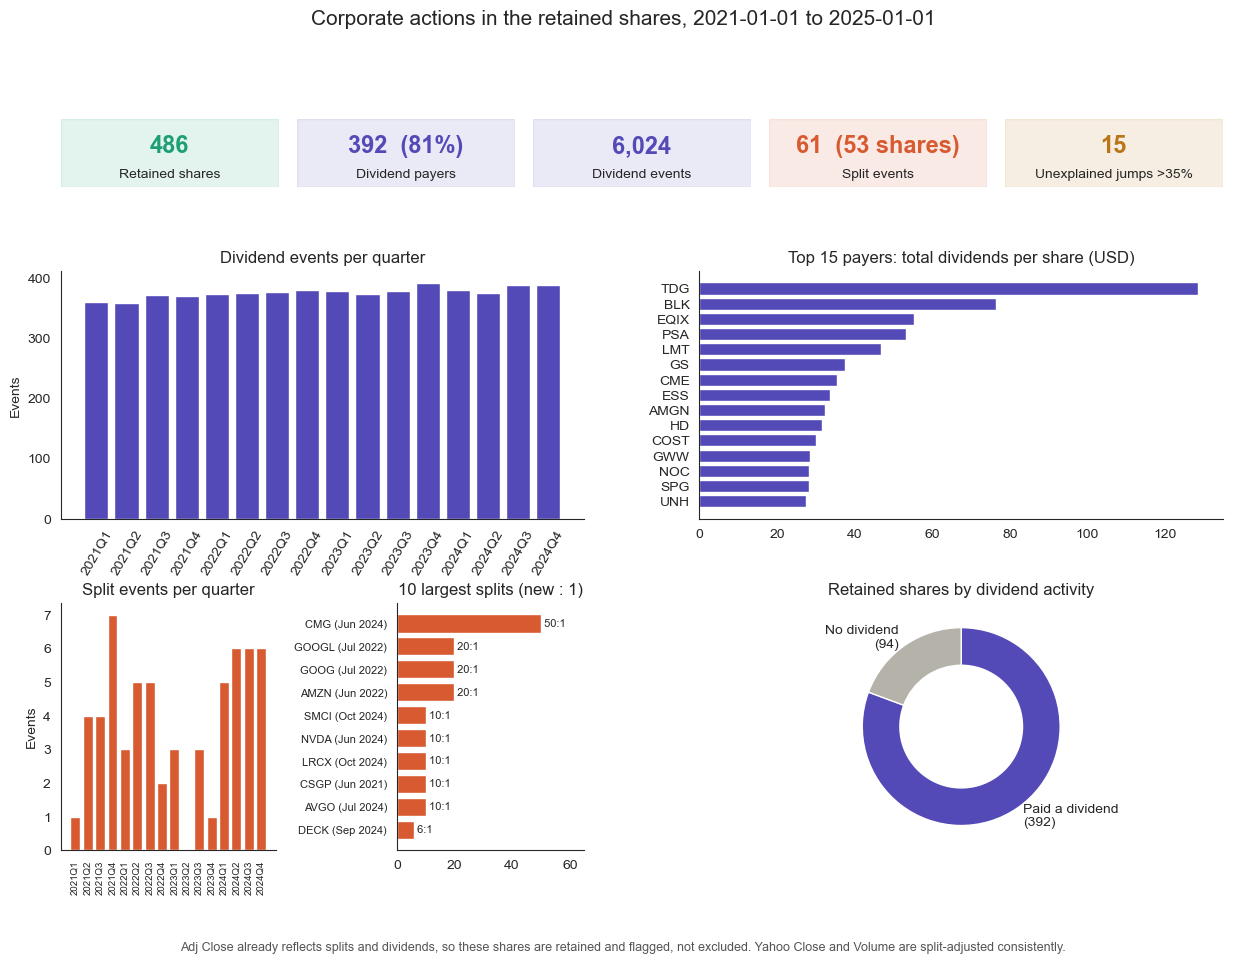

In [101]:
# ---------- corporate actions: diagnostic + infographic (retained shares only) ----------
import matplotlib.gridspec as gridspec
START_TS, END_TS = pd.Timestamp(start), pd.Timestamp(end)

# 1. why might the dividend check show nothing? look at the raw column first
print("Dividends column present   :", "Dividends" in df_all.columns)
print("Dividends non-missing rows :", int(df_all["Dividends"].notna().sum()), "| rows > 0:", int((df_all["Dividends"].fillna(0) > 0).sum()))

r = df_all[df_all["Ticker"].isin(keep)]                         # retained shares only
div_ev = r[r["Dividends"].fillna(0) > 0]
spl_ev = r[r["Stock Splits"].fillna(0) > 0]
n_ret, payers = len(keep), div_ev["Ticker"].nunique()
n_jump = int(jumps["Ticker"].isin(keep).sum())
print(f"Dividend events: {len(div_ev)} | payers: {payers} | total per share: ${div_ev['Dividends'].sum():,.2f} | split events: {len(spl_ev)}")
if len(div_ev) == 0:
    print("-> No dividend rows found. Re-run the download with actions=True and auto_adjust=False, then rebuild df_all.")

# 2. infographic
C = {"div": "#534AB7", "ok": "#1D9E75", "grey": "#B4B2A9", "split": "#D85A30", "warn": "#BA7517"}
fig = plt.figure(figsize=(15, 9.5))
gs = gridspec.GridSpec(3, 2, height_ratios=[0.55, 2, 2], hspace=0.45, wspace=0.22)

tiles = [("Retained shares", f"{n_ret}", C["ok"]),
         ("Dividend payers", f"{payers}  ({payers / max(n_ret, 1) * 100:.0f}%)", C["div"]),
         ("Dividend events", f"{len(div_ev):,}", C["div"]),
         ("Split events", f"{len(spl_ev)}  ({spl_ev['Ticker'].nunique()} shares)", C["split"]),
         ("Unexplained jumps >35%", f"{n_jump}", C["warn"])]
top = gs[0, :].subgridspec(1, len(tiles), wspace=0.08)
for i, (lab, val, col) in enumerate(tiles):
    a = fig.add_subplot(top[0, i]); a.axis("off")
    a.add_patch(plt.Rectangle((0, 0), 1, 1, transform=a.transAxes, color=col, alpha=0.12))
    a.text(0.5, 0.60, val, ha="center", va="center", fontsize=17, fontweight="bold", color=col, transform=a.transAxes)
    a.text(0.5, 0.18, lab, ha="center", va="center", fontsize=10, transform=a.transAxes)

# dividend events per quarter
ax1 = fig.add_subplot(gs[1, 0])
if len(div_ev):
    q = div_ev.groupby(div_ev["Date"].dt.to_period("Q")).size()
    ax1.bar(q.index.astype(str), q.values, color=C["div"]); ax1.tick_params(axis="x", rotation=60)
else:
    ax1.text(0.5, 0.5, "No dividend events found", ha="center", va="center", transform=ax1.transAxes)
ax1.set_title("Dividend events per quarter"); ax1.set_ylabel("Events")

# top dividend payers (total dividends per share, USD)
ax2 = fig.add_subplot(gs[1, 1])
if len(div_ev):
    tp = div_ev.groupby("Ticker")["Dividends"].sum().nlargest(15).sort_values()
    ax2.barh(tp.index, tp.values, color=C["div"])
else:
    ax2.text(0.5, 0.5, "No dividend events found", ha="center", va="center", transform=ax2.transAxes)
ax2.set_title("Top 15 payers: total dividends per share (USD)")

# splits: count per quarter (when) + the 10 largest ratios (how big), instead of labelling every split
sub = gs[2, 0].subgridspec(1, 2, wspace=0.6, width_ratios=[1.15, 1])
ax3a, ax3b = fig.add_subplot(sub[0, 0]), fig.add_subplot(sub[0, 1])
if len(spl_ev):
    sq = spl_ev.groupby(spl_ev["Date"].dt.to_period("Q")).size()
    sq = sq.reindex(pd.period_range(START_TS,END_TS - pd.Timedelta(days=1), freq="Q"), fill_value=0)
    ax3a.bar(sq.index.astype(str), sq.values, color=C["split"]); ax3a.tick_params(axis="x", rotation=90, labelsize=7)
    ax3a.set_title("Split events per quarter"); ax3a.set_ylabel("Events")
    big = spl_ev.nlargest(10, "Stock Splits").sort_values("Stock Splits")
    ax3b.barh([f"{t} ({d:%b %Y})" for t, d in zip(big["Ticker"], big["Date"])], big["Stock Splits"], color=C["split"])
    for i_, v_ in enumerate(big["Stock Splits"]):
        ax3b.text(v_, i_, f" {v_:g}:1", va="center", fontsize=8)
    ax3b.set_xlim(0, big["Stock Splits"].max() * 1.3); ax3b.tick_params(axis="y", labelsize=8)
    ax3b.set_title("10 largest splits (new : 1)")
else:
    for a_ in (ax3a, ax3b):
        a_.text(0.5, 0.5, "No split events in the retained shares", ha="center", va="center", transform=a_.transAxes)

# payers vs non-payers
ax4 = fig.add_subplot(gs[2, 1])
ax4.pie([payers, max(n_ret - payers, 0)], labels=[f"Paid a dividend\n({payers})", f"No dividend\n({n_ret - payers})"],
        colors=[C["div"], C["grey"]], startangle=90, counterclock=False, wedgeprops=dict(width=0.38, edgecolor="white"))
ax4.set_title("Retained shares by dividend activity")

for a in (ax1, ax2, ax3a, ax3b):
    for s_ in ("top", "right"): a.spines[s_].set_visible(False)
fig.suptitle(f"Corporate actions in the retained shares, {start} to {end}", fontsize=15, y=0.995)
fig.text(0.5, 0.005, "Adj Close already reflects splits and dividends, so these shares are retained and flagged, not excluded. "
         "Yahoo Close and Volume are split-adjusted consistently.", ha="center", fontsize=9, color="#555")
plt.savefig(f"{OUT_DIR}/corporate_actions_infographic.png", dpi=200, bbox_inches="tight"); plt.show()

In [102]:
df_clean.shape

(489435, 10)

In [103]:
if "Date added" in sp500_df.columns:
    added = pd.to_datetime(sp500_df["Date added"], errors="coerce")
    print(f"Constituents added after {start}: {(added > START_TS).sum()} of {len(added)}")
    print("Historical members that left the index before retrieval are NOT in the list at all.")

Constituents added after 2021-01-01: 89 of 503
Historical members that left the index before retrieval are NOT in the list at all.


### Weekly return and weekly beta

##### Mean weekly return

In [104]:
prices_wide = (df_clean
               .pivot(index='Date', columns='Ticker', values='Adj Close')
               .sort_index())

def calculate_weekly_returns(prices, shares=None):
    """prices: DataFrame, dates as rows and tickers as columns (Adj Close)."""
    if shares is not None:
        prices = prices[shares]
    prices = prices.copy()
    prices.index = pd.to_datetime(prices.index)
    weekly = prices.sort_index().resample("W-FRI").last()

    # keep only complete calendar weeks inside the study period
    week_monday = weekly.index - pd.Timedelta(days=4)
    weekly = weekly[(week_monday >= start) & (weekly.index < end)]

    return weekly.pct_change(fill_method=None)

weekly_return = calculate_weekly_returns(prices_wide)
weekly_return = weekly_return.iloc[1:]       # first week has no preceding week (blank return)
print(weekly_return.shape)

(207, 487)


In [105]:
weekly_return = calculate_weekly_returns(prices_wide)

In [106]:
BENCH_SYMBOL = '^GSPC'

market_ret = weekly_return[BENCH_SYMBOL]
share_ret  = weekly_return.drop(columns=BENCH_SYMBOL)

# Use only weeks where both the share and the benchmark have a return (common week labels)
aligned = share_ret.where(market_ret.notna(), axis=0)

# Arithmetic mean weekly return: one value per share
mean_weekly_return = aligned.mean().rename('Mean_Weekly_Return')

print('Shares:', len(mean_weekly_return))
print('Weekly observations per share:', aligned.notna().sum().min(), 'to', aligned.notna().sum().max())
print(mean_weekly_return.describe())
mean_weekly_return.sort_values(ascending=False).head(10)

Shares: 486
Weekly observations per share: 207 to 207
count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
Name: Mean_Weekly_Return, dtype: float64


Ticker
SMCI    0.017772
NVDA    0.013624
VRT     0.012583
VST     0.011395
FIX     0.011297
CVNA    0.010964
ANET    0.010310
TRGP    0.010152
AVGO    0.010133
AXON    0.009767
Name: Mean_Weekly_Return, dtype: float64

In [107]:
t = mean_weekly_return.index[0]
print(t, mean_weekly_return[t], weekly_return[t].dropna().mean())   # the two numbers should match

A 0.001120608647349219 0.001120608647349219


#### Weekly beta

In [108]:
def calculate_weekly_beta(weekly_return, market_return, min_weeks=52):
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_return.columns:
        paired = pd.concat(
            [weekly_return[share].rename("share"),
             market_return.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [109]:
BENCH_SYMBOL = '^GSPC'

market_ret = weekly_return[BENCH_SYMBOL]                  # benchmark column
share_ret  = weekly_return.drop(columns=BENCH_SYMBOL)     # shares only

beta_df = calculate_weekly_beta(share_ret, market_ret)
print(beta_df['Paired_weeks'].value_counts())             # expect 207 for every share
beta_df.describe()

Paired_weeks
207    486
Name: count, dtype: int64


,Beta,Paired_weeks
count,486.000000,486.0
mean,0.973695,207.0
std,0.407339,0.0
min,0.055453,207.0
25%,0.666599,207.0
50%,0.950610,207.0
75%,1.179538,207.0
max,3.778560,207.0


In [110]:
beta_df.head()

,Beta,Paired_weeks
Share,,
A,1.074723,207
AAPL,1.174836,207
ABBV,0.425365,207
ABNB,1.472709,207
ABT,0.583543,207


### Recency Calculation

In [111]:
OBS_DATE = pd.Timestamp('2024-12-31')
vol = (df_clean[df_clean['Ticker'] != BENCH_SYMBOL]
       .pivot(index='Date', columns='Ticker', values='Volume')
       .sort_index())
vol = vol.loc[:OBS_DATE]
print('Last date in data:', vol.index[-1].date())

baseline = vol.shift(1).rolling(20).mean()

# 3. High-volume day: volume > 2 x baseline (first 20 sessions have no baseline, so never qualify)
high = (vol > 2 * baseline) & baseline.notna()

# 4. Latest qualifying day per share, over the whole valid history
def last_event(col):
    days = col.index[col]
    return days[-1] if len(days) else pd.NaT

last_event_date = high.apply(last_event)

# 5. Recency = calendar days from that event to the observation date (NaN if no event, never 0)
recency = (OBS_DATE - last_event_date).dt.days.rename('Recency')

rfm = pd.concat([last_event_date.rename('Last_Event_Date'), recency], axis=1)
print('Shares with no event (Recency missing):', int(rfm['Recency'].isna().sum()))
rfm.head()

Last date in data: 2024-12-31
Shares with no event (Recency missing): 0


,Last_Event_Date,Recency
Ticker,,
A,2024-12-20,11
AAPL,2024-12-20,11
ABBV,2024-12-20,11
ABNB,2024-12-20,11
ABT,2024-12-20,11


In [112]:
rfm

,Last_Event_Date,Recency
Ticker,,
A,2024-12-20,11
AAPL,2024-12-20,11
ABBV,2024-12-20,11
ABNB,2024-12-20,11
ABT,2024-12-20,11
...,...,...
XYZ,2024-11-12,49
YUM,2024-11-05,56
ZBH,2024-12-20,11


In [113]:
print(rfm['Recency'].value_counts().head())

Recency
11    353
36     17
55     11
60      6
46      6
Name: count, dtype: int64


### Frequency Calculation

In [114]:
RFM_WIN = 60

# 1. Last 60 trading sessions ending on the observation date
#    ('high' was built on the FULL history in the Recency cell, so every window day has its 20-session baseline)
window = high.loc[:OBS_DATE].tail(RFM_WIN)
assert len(window) == RFM_WIN and window.index[-1] == OBS_DATE
print(f'Window: {window.index[0].date()} -> {window.index[-1].date()} ({len(window)} sessions)')

# 2. Frequency = number of qualifying days in the window, per share
frequency = window.sum().astype(int).rename('Frequency')

# 3. Add it to the RFM table
rfm['Frequency'] = frequency

print(frequency.describe())
print('\nDistribution of Frequency:')
print(frequency.value_counts().sort_index().to_string())

Window: 2024-10-07 -> 2024-12-31 (60 sessions)
count    486.000000
mean       2.989712
std        1.330800
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
Name: Frequency, dtype: float64

Distribution of Frequency:
Frequency
0     10
1     42
2    130
3    149
4     94
5     45
6     11
7      3
8      2


### Monetary Calculation

In [115]:
close = (df_clean[df_clean['Ticker'] != BENCH_SYMBOL]
         .pivot(index='Date', columns='Ticker', values='Close')
         .sort_index()
         .loc[:OBS_DATE])
close = close[vol.columns]                       # same columns, same order as volume

# 2. Daily traded value = Close x Volume
traded_value = close * vol.loc[:OBS_DATE]

# 3. Latest 60 trading sessions ending on the observation date
window_tv = traded_value.tail(RFM_WIN)
assert len(window_tv) == RFM_WIN and window_tv.index[-1] == OBS_DATE
print(f'Window: {window_tv.index[0].date()} -> {window_tv.index[-1].date()} ({len(window_tv)} sessions)')

# 4. Monetary = sum of the 60 daily values (USD)
monetary = window_tv.sum().rename('Monetary')
rfm['Monetary'] = monetary

print(monetary.describe().apply(lambda x: f'{x:,.0f}'))
print('\nTop 5 by traded value:')
print(monetary.sort_values(ascending=False).head(5).apply(lambda x: f'${x:,.0f}'))

Window: 2024-10-07 -> 2024-12-31 (60 sessions)
count                  486
mean        39,404,191,889
std        129,138,833,233
min          1,297,482,617
25%         10,195,173,392
50%         16,683,821,505
75%         32,276,893,044
max      1,847,697,379,222
Name: Monetary, dtype: object

Top 5 by traded value:
Ticker
TSLA    $1,847,697,379,222
NVDA    $1,825,336,654,239
AAPL      $623,303,377,707
MSFT      $534,898,232,235
AMZN      $468,177,023,567
Name: Monetary, dtype: object


In [116]:
rfm

,Last_Event_Date,Recency,Frequency,Monetary
Ticker,,,,
A,2024-12-20,11,2,1.400180e+10
AAPL,2024-12-20,11,2,6.233034e+11
ABBV,2024-12-20,11,3,6.837054e+10
ABNB,2024-12-20,11,3,3.652850e+10
ABT,2024-12-20,11,1,3.523027e+10
...,...,...,...,...
XYZ,2024-11-12,49,5,4.052406e+10
YUM,2024-11-05,56,1,1.339492e+10
ZBH,2024-12-20,11,2,9.609458e+09


### 1.5

In [117]:
no_event = rfm.index[rfm["Recency"].isna()]
RFM_WIN, BASE_WIN, MULT = 60, 20, 2.0
def volume_event_frame(volume, close_):
    d = pd.DataFrame({"Close": close_, "Volume": volume})
    d["Baseline20"]  = d["Volume"].shift(1).rolling(BASE_WIN).mean()
    d["Threshold"]   = MULT * d["Baseline20"]
    d["HighVolume"]  = (d["Volume"] > d["Threshold"]) & d["Baseline20"].notna()
    d["TradedValue"] = d["Close"] * d["Volume"]
    return d

# ---- unit tests of the rules (brief's own examples) ----
idx = pd.bdate_range("2024-01-01", periods=90)
v = pd.Series(1_000_000.0, index=idx); c = pd.Series(100.0, index=idx)
v.iloc[-1] = 2_500_000          # qualifies (threshold 2.0m)
v.iloc[-30] = 1_800_000         # does not qualify
t_ = volume_event_frame(v, c)
assert t_["Threshold"].iloc[-1] == 2_000_000 and t_["HighVolume"].iloc[-1] and not t_["HighVolume"].iloc[-30]
assert (idx[-1] - t_.index[t_["HighVolume"]][-1]).days == 0                      # event on obs date -> R = 0
assert (pd.Timestamp("2024-09-20") - pd.Timestamp("2024-09-15")).days == 5       # brief's recency example
assert 100 * 2_000_000 == 200_000_000                                            # brief's monetary example
flat = volume_event_frame(pd.Series(1_000_000.0, index=idx), c)
assert not flat["HighVolume"].any()                                              # no event -> Recency must be NaN, not 0
print("Unit tests passed")

# ---- alignment checks on the real data ----
s0 = vol.columns[0]
d0 = volume_event_frame(vol[s0], close[s0])
manual = vol[s0].iloc[-21:-1].mean()
assert np.isclose(d0["Baseline20"].iloc[-1], manual)                             # baseline = 20 PRECEDING sessions
v_mod = vol[s0].copy(); v_mod.iloc[-1] *= 1000
assert np.isclose(volume_event_frame(v_mod, close[s0])["Baseline20"].iloc[-1], manual)   # tested day excluded from its own baseline
assert (high[s0] == d0["HighVolume"]).all()                                      # helper agrees with vectorised version
assert vol.shape[0] >= BASE_WIN + RFM_WIN                                        # enough history for 20 + 60 sessions
print(f"Alignment checks passed | first testable day {vol.index[BASE_WIN].date()} | no-event shares: {len(no_event)}")

# ---- worked example for one share ----
EXAMPLE = "ABNB" if "ABNB" in vol.columns else vol.columns[0]
ex = volume_event_frame(vol[EXAMPLE], close[EXAMPLE])
win = ex.tail(RFM_WIN); events = ex.index[ex["HighVolume"]]
print(f"WORKED EXAMPLE: {EXAMPLE} | observation date {OBS_DATE.date()} | window {win.index[0].date()} -> {win.index[-1].date()}")
print(f"Baseline on obs date = mean of {ex.index[-21].date()}..{ex.index[-2].date()} = {ex['Baseline20'].iloc[-1]:,.0f}; threshold = {ex['Threshold'].iloc[-1]:,.0f}")
if len(events):
    print(f"RECENCY  : last high-volume day {events[-1].date()} -> {(OBS_DATE - events[-1]).days} calendar days")
print(f"FREQUENCY: {int(win['HighVolume'].sum())} days -> {[str(x.date()) for x in win.index[win['HighVolume']]]}")
print(f"MONETARY : ${win['TradedValue'].sum():,.0f}")
assert (rfm.loc[EXAMPLE, "Frequency"], round(rfm.loc[EXAMPLE, "Monetary"])) == (int(win["HighVolume"].sum()), round(win["TradedValue"].sum()))
print(win.loc[win["HighVolume"], ["Close", "Volume", "Baseline20", "Threshold", "TradedValue"]].round(2).to_string())
win.to_csv(f"{OUT_DIR}/worked_example_{EXAMPLE}.csv")

Unit tests passed
Alignment checks passed | first testable day 2021-02-02 | no-event shares: 0
WORKED EXAMPLE: ABNB | observation date 2024-12-31 | window 2024-10-07 -> 2024-12-31
Baseline on obs date = mean of 2024-12-02..2024-12-30 = 4,500,740; threshold = 9,001,480
RECENCY  : last high-volume day 2024-12-20 -> 11 calendar days
FREQUENCY: 3 days -> ['2024-11-07', '2024-11-08', '2024-12-20']
MONETARY : $36,528,503,216
             Close      Volume  Baseline20  Threshold   TradedValue
Date                                                               
2024-11-07  147.37  11988900.0   3296530.0  6593060.0  1.766804e+09
2024-11-08  134.61  19189000.0   3742975.0  7485950.0  2.583031e+09
2024-12-20  134.21  15471700.0   4390195.0  8780390.0  2.076457e+09


### 2nd Question

#### Feature Preparation

In [118]:
BENCH_SYMBOL = '^GSPC'

# 1. Share and week rows (the week labels come from your weekly_return table)
base = (weekly_return
        .drop(columns=BENCH_SYMBOL)
        .rename_axis('Week')
        .reset_index()
        .melt(id_vars='Week', var_name='Share', value_name='Weekly_Return')
        .sort_values(['Share', 'Week'])
        .reset_index(drop=True))

# 2. Make the two per-share tables use the same key column: Share
mwr = mean_weekly_return.rename('Mean_Weekly_Return').rename_axis('Share').reset_index()   # if it is a Series
bt  = beta_df[['Beta']].rename_axis('Share').reset_index()

# 3. Merge: every row gets that share's mean return and beta
combined = (base[['Week', 'Share']]
            .merge(mwr, on='Share', how='left')
            .merge(bt,  on='Share', how='left'))

print(combined.shape)
combined.head()

(101088, 4)


,Week,Share,Mean_Weekly_Return,Beta
0,2021-01-08,A,0.001121,1.074723
1,2021-01-15,A,0.001121,1.074723
2,2021-01-22,A,0.001121,1.074723
3,2021-01-29,A,0.001121,1.074723
4,2021-02-05,A,0.001121,1.074723


In [119]:
rfm.head()

,Last_Event_Date,Recency,Frequency,Monetary
Ticker,,,,
A,2024-12-20,11,2,1.400180e+10
AAPL,2024-12-20,11,2,6.233034e+11
ABBV,2024-12-20,11,3,6.837054e+10
ABNB,2024-12-20,11,3,3.652850e+10
ABT,2024-12-20,11,1,3.523027e+10


Shares in common valid set: 486
Final_Status
Included (common valid set)    486
Excluded                        17
RAW FEATURES
                            mean        median           std           min           max    skew  IQR_outliers  outlier_%
Mean_Weekly_Return  3.000000e-03  3.000000e-03  3.000000e-03 -4.000000e-03  1.800000e-02   0.868            15        3.1
Beta                9.740000e-01  9.510000e-01  4.070000e-01  5.500000e-02  3.779000e+00   1.104            10        2.1
Recency             2.040700e+01  1.100000e+01  2.134200e+01  4.000000e+00  2.220000e+02   3.646           115       23.7
Frequency           2.990000e+00  3.000000e+00  1.331000e+00  0.000000e+00  8.000000e+00   0.425             2        0.4
Monetary            3.940419e+10  1.668382e+10  1.291388e+11  1.297483e+09  1.847697e+12  11.684            45        9.3


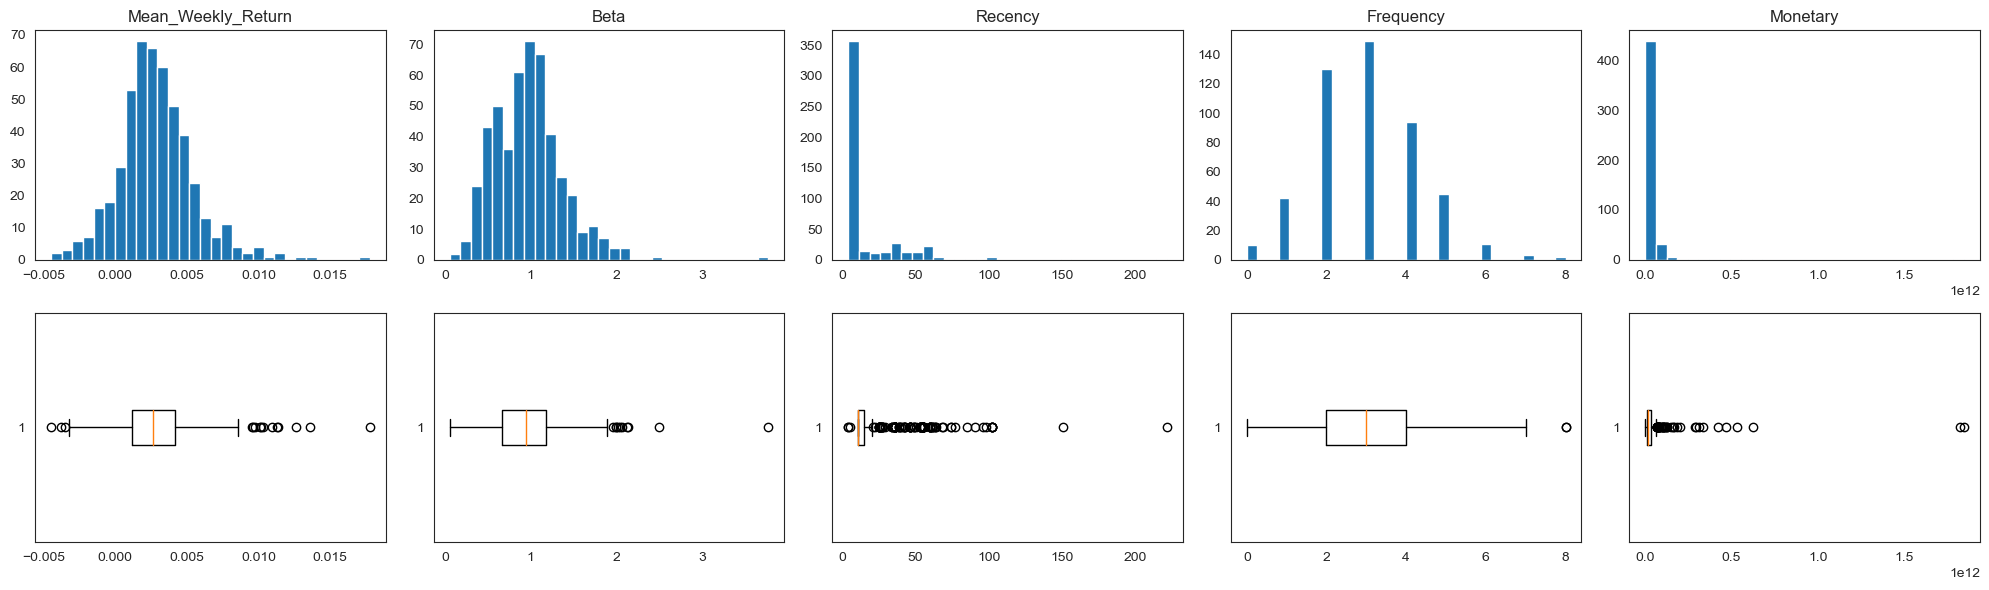


Skew of Monetary before / after log1p: 11.68 -> 1.08

ACTIVITY MATRIX AFTER log1p
                  mean  median     std     min      max   skew  IQR_outliers  outlier_%
Recency         20.407  11.000  21.342   4.000  222.000  3.646           115       23.7
Frequency        2.990   3.000   1.331   0.000    8.000  0.425             2        0.4
log1p_Monetary  23.682  23.538   0.942  20.984   28.245  1.079            13        2.7

Standardised means ~0, std ~1:
      Mean_Weekly_Return   Beta
mean              -0.000 -0.000
std                1.001  1.001
      Recency  Frequency  log1p_Monetary
mean   -0.000     -0.000          -0.000
std     1.001      1.001           1.001

FOUR BASELINE SOLUTIONS
     Matrix        Method  k  Silhouette           Sizes
Risk_Return        KMeans  3       0.329 [119, 202, 165]
Risk_Return Agglomerative  3       0.274  [230, 92, 164]
   Activity        KMeans  3       0.325  [270, 64, 152]
   Activity Agglomerative  3       0.304  [250, 82, 154]


In [120]:
# ! pip install -U threadpoolctl scikit-learn      # only if KMeans raises the threadpool error
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# ---------- 1. common valid share set (all five features present) ----------
all_feat = pd.concat([mean_weekly_return.rename("Mean_Weekly_Return").rename_axis("Share"),
                      beta_df["Beta"].rename_axis("Share"),
                      rfm[["Recency", "Frequency", "Monetary"]].rename_axis("Share")],
                     axis=1, join="inner").dropna()
print("Shares in common valid set:", len(all_feat))

# ---------- final inclusion / exclusion log ----------
final_log = check[["Reason", "Status"]].copy()
final_log["Final_Status"] = final_log["Status"]; final_log["Final_Reason"] = final_log["Reason"]
for tk in final_log.index[final_log["Status"] == "Included"]:
    if tk not in all_feat.index:
        why = "no high-volume event (Recency missing)" if tk in no_event else "missing weekly feature or fewer than 52 paired weeks"
        final_log.loc[tk, ["Final_Status", "Final_Reason"]] = ["Excluded from clustering", why]
final_log.loc[final_log["Final_Status"] == "Included", "Final_Status"] = "Included (common valid set)"
final_log.to_csv(f"{OUT_DIR}/final_inclusion_exclusion_log.csv")
print(final_log["Final_Status"].value_counts().to_string())

# ---------- 2. inspect skew and outliers ----------
def inspect(df):
    q1, q3 = df.quantile(.25), df.quantile(.75); iqr = q3 - q1
    out = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
    return pd.DataFrame({"mean": df.mean(), "median": df.median(), "std": df.std(), "min": df.min(), "max": df.max(),
                         "skew": df.skew(), "IQR_outliers": out, "outlier_%": (out / len(df) * 100).round(1)})

print("RAW FEATURES"); print(inspect(all_feat).round(3).to_string())

fig, ax = plt.subplots(2, 5, figsize=(20, 6))
for i, c_ in enumerate(all_feat.columns):
    ax[0, i].hist(all_feat[c_], bins=30, edgecolor="white"); ax[0, i].set_title(c_)
    ax[1, i].boxplot(all_feat[c_], vert=False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/feature_skew_outliers.png", dpi=150); plt.show()

# ---------- 3. two separate matrices; log1p on Monetary only ----------
risk_return = all_feat[["Mean_Weekly_Return", "Beta"]].copy()
activity    = all_feat[["Recency", "Frequency", "Monetary"]].copy()
activity["Monetary"] = np.log1p(activity["Monetary"])
activity = activity.rename(columns={"Monetary": "log1p_Monetary"})
print("\nSkew of Monetary before / after log1p:", round(all_feat["Monetary"].skew(), 2), "->", round(activity["log1p_Monetary"].skew(), 2))
print("\nACTIVITY MATRIX AFTER log1p"); print(inspect(activity).round(3).to_string())

# ---------- 4. standardise each matrix separately ----------
def standardise(df):
    return pd.DataFrame(StandardScaler().fit_transform(df), index=df.index, columns=df.columns)
X_risk, X_act = standardise(risk_return), standardise(activity)
print("\nStandardised means ~0, std ~1:"); print(X_risk.agg(["mean", "std"]).round(3)); print(X_act.agg(["mean", "std"]).round(3))

# ---------- 5. four baseline solutions ----------
def fit(method, X, k, seed=SEED):
    if method == "KMeans":
        return KMeans(n_clusters=k, n_init=N_INIT, random_state=seed, algorithm="elkan").fit_predict(X)
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)

matrices = {"Risk_Return": X_risk, "Activity": X_act}
K = 3
summary = []
baseline_labels = pd.DataFrame(index=all_feat.index)
for name, X in matrices.items():
    for method in ["KMeans", "Agglomerative"]:
        lab = fit(method, X, K)
        baseline_labels[f"{name}_{method}"] = lab
        summary.append({"Matrix": name, "Method": method, "k": K, "Silhouette": silhouette_score(X, lab), "Sizes": np.bincount(lab).tolist()})
print("\nFOUR BASELINE SOLUTIONS"); print(pd.DataFrame(summary).round(3).to_string(index=False))
all_feat.join(baseline_labels).to_csv(f"{OUT_DIR}/feature_table_baseline_assignments_k3.csv")   # one row per included share

Both matrices: 486 shares, no missing or infinite values
Correlations are identical before and after standardising (scaling only shifts and rescales)

     Matrix            Feature  mean  std  skew  kurtosis   min  max  |z|>3  |z|>4
Risk_Return Mean_Weekly_Return  -0.0  1.0  0.87      3.02 -2.77 5.63      6      2
Risk_Return               Beta  -0.0  1.0  1.10      4.47 -2.26 6.89      2      1
   Activity            Recency  -0.0  1.0  3.65     21.00 -0.77 9.46     11      2
   Activity          Frequency  -0.0  1.0  0.42      0.54 -2.25 3.77      5      0
   Activity     log1p_Monetary  -0.0  1.0  1.08      2.69 -2.87 4.85      7      2

Note: standardising does not change skew. Skew is reduced only by log1p, so Recency stays skewed and its outliers remain.


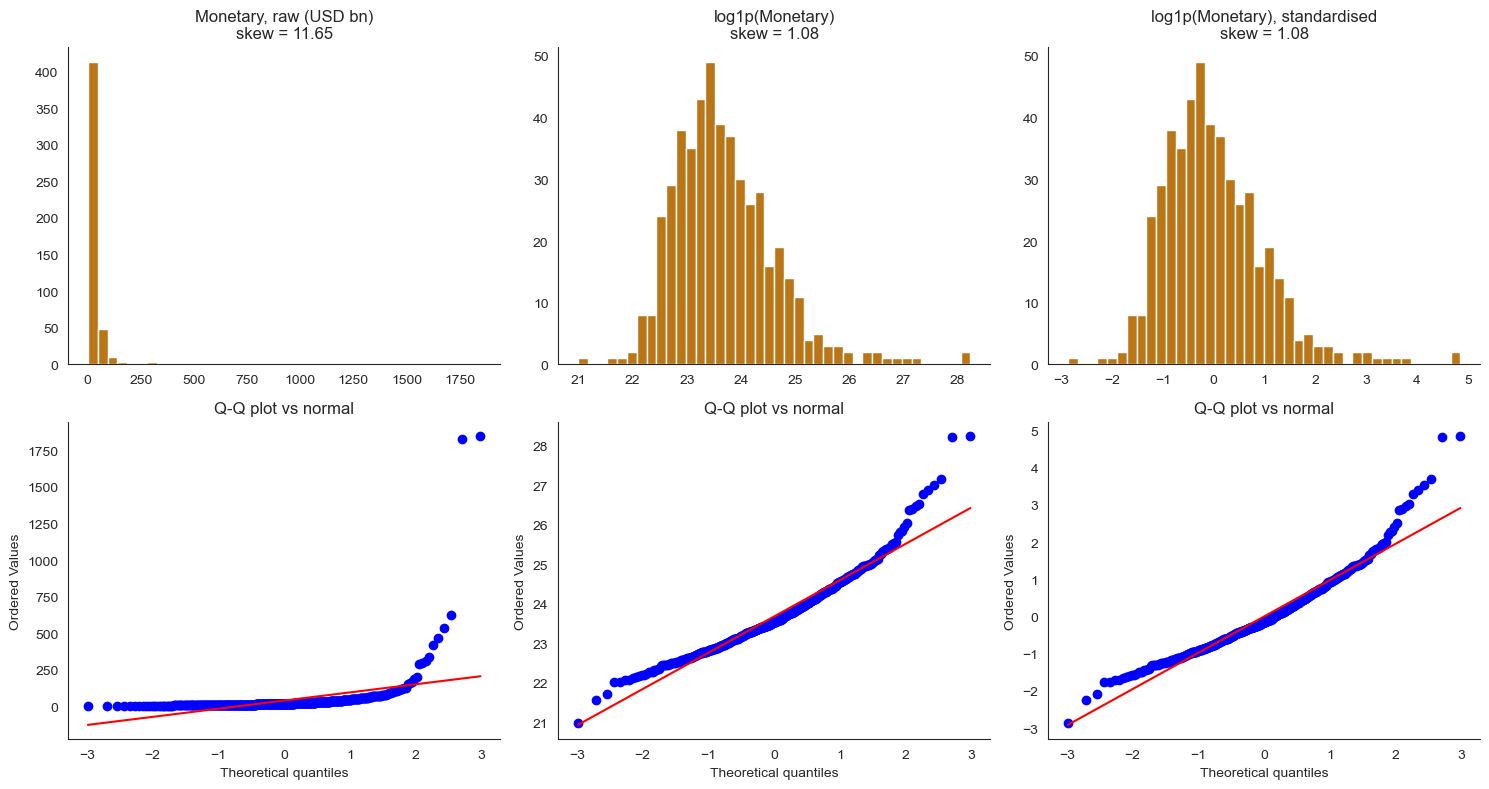

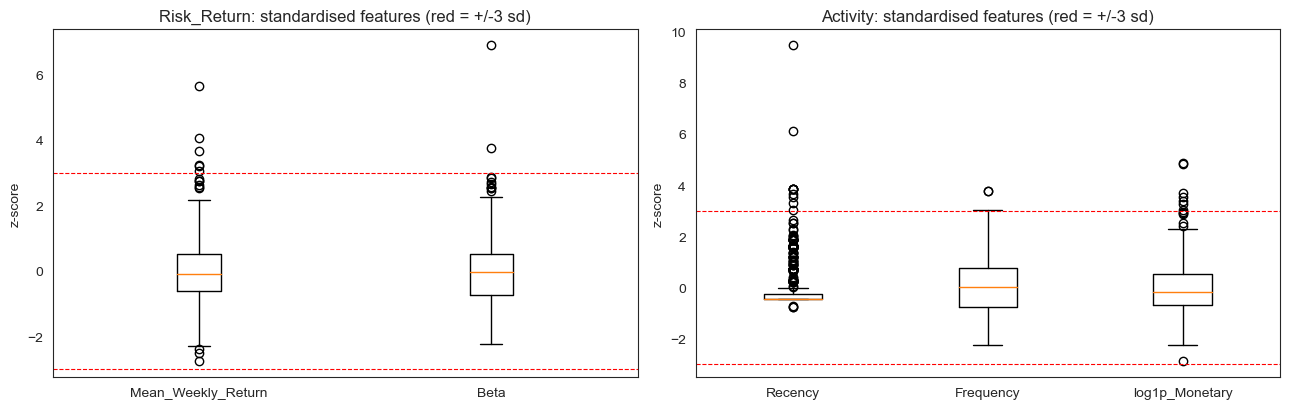

In [121]:
# checks_after_transform
from scipy import stats

# ---- 1. integrity: same shares, no NaN or infinite values in either final matrix ----
for name, X in matrices.items():
    assert X.shape[0] == len(all_feat) and np.isfinite(X.values).all(), f"problem in {name}"
print(f"Both matrices: {len(all_feat)} shares, no missing or infinite values")

# ---- 2. scaling must not change relationships: correlations before and after standardising ----
assert np.allclose(risk_return.corr().values, X_risk.corr().values) and np.allclose(activity.corr().values, X_act.corr().values)
print("Correlations are identical before and after standardising (scaling only shifts and rescales)")

# ---- 3. shape and outliers in STANDARDISED units ----
rows = []
for name, X in matrices.items():
    for c_ in X.columns:
        z = X[c_]
        rows.append({"Matrix": name, "Feature": c_, "mean": z.mean(), "std": z.std(ddof=0), "skew": z.skew(), "kurtosis": z.kurt(),
                     "min": z.min(), "max": z.max(), "|z|>3": int((z.abs() > 3).sum()), "|z|>4": int((z.abs() > 4).sum())})
zchk = pd.DataFrame(rows); print(); print(zchk.round(2).to_string(index=False))
zchk.to_csv(f"{OUT_DIR}/standardised_feature_checks.csv", index=False)
print("\nNote: standardising does not change skew. Skew is reduced only by log1p, so Recency stays skewed and its outliers remain.")

# ---- 4. Monetary: raw vs log1p vs standardised, with Q-Q plots against a normal distribution ----
raw_m = all_feat["Monetary"]; log_m = activity["log1p_Monetary"]; std_m = X_act["log1p_Monetary"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (v, t_) in enumerate([(raw_m / 1e9, "Monetary, raw (USD bn)"), (log_m, "log1p(Monetary)"), (std_m, "log1p(Monetary), standardised")]):
    ax[0, j].hist(v, bins=40, color="#BA7517", edgecolor="white"); ax[0, j].set_title(f"{t_}\nskew = {stats.skew(v):.2f}")
    stats.probplot(v, dist="norm", plot=ax[1, j]); ax[1, j].set_title("Q-Q plot vs normal")
    for a_ in (ax[0, j], ax[1, j]): a_.spines["top"].set_visible(False); a_.spines["right"].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/monetary_before_after.png", dpi=200); plt.show()

# ---- 5. all standardised features on one scale: box plots with +/-3 reference lines ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a_, (name, X) in zip(ax, matrices.items()):
    a_.boxplot([X[c_] for c_ in X.columns]); a_.set_xticklabels(X.columns)
    for y_ in (-3, 3): a_.axhline(y_, color="red", ls="--", lw=0.8)
    a_.set_title(f"{name}: standardised features (red = +/-3 sd)"); a_.set_ylabel("z-score")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/standardised_boxplots.png", dpi=200); plt.show()

### Agglomerative clustering

     Matrix        Method  k  Silhouette  Min_%                             Sizes  Feasible
Risk_Return Agglomerative  2       0.339   18.9                         [394, 92]      True
Risk_Return Agglomerative  3       0.274   18.9                    [230, 164, 92]      True
Risk_Return Agglomerative  4       0.282    9.9                [182, 164, 92, 48]      True
Risk_Return Agglomerative  5       0.304    9.9             [182, 98, 92, 66, 48]      True
Risk_Return Agglomerative  6       0.320    1.0          [182, 98, 87, 66, 48, 5]     False
Risk_Return Agglomerative  7       0.324    1.0      [160, 98, 87, 66, 48, 22, 5]     False
Risk_Return Agglomerative  8       0.321    1.0  [160, 98, 66, 56, 48, 31, 22, 5]     False
   Activity Agglomerative  2       0.368   16.9                         [404, 82]      True
   Activity Agglomerative  3       0.304   16.9                    [250, 154, 82]      True
   Activity Agglomerative  4       0.289    8.8                [207, 154, 82, 43

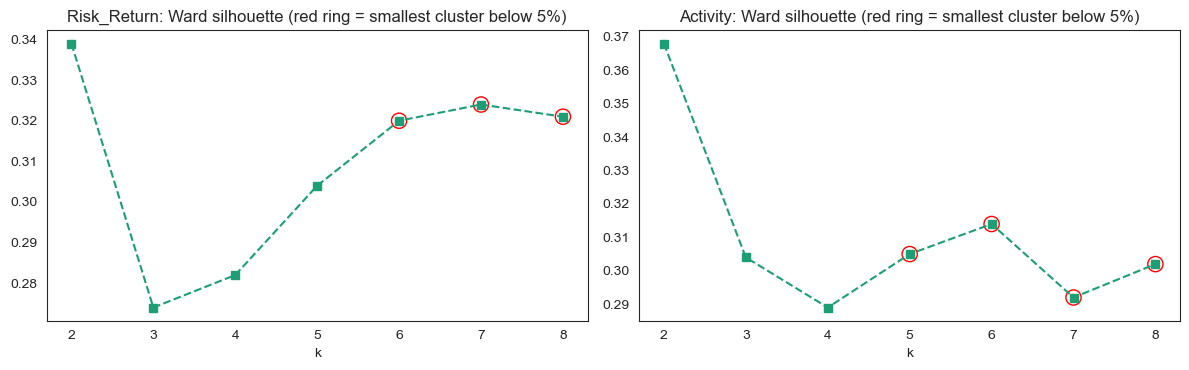


=== Risk_Return, Ward, k = 3 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0017       1.0384  230  47.3
1                           0.0055       1.2177   92  18.9
2                           0.0033       0.5777  164  33.7

=== Risk_Return, Ward, k = 4 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0033       0.5777  164  33.7
1                           0.0055       1.2177   92  18.9
2                           0.0017       0.9644  182  37.4
3                           0.0025       1.5139   48   9.9

=== Risk_Return, Ward, k = 5 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0055       1.2177   92  18.9
1                           0.0025       1.5139   48   9.9
2            

In [122]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist

SEED, N_INIT, MIN_FRAC = 42, 50, 0.05

COLS = {"Risk_Return": ["Mean_Weekly_Return", "Beta"], "Activity": ["Recency", "Frequency", "Monetary"]}
def profile(labels, cols):
    """cluster medians in ORIGINAL units, with sizes"""
    g = all_feat.assign(Cluster=labels).groupby("Cluster")
    out = g[cols].median().add_suffix("_median")
    out["n"] = g.size(); out["%"] = (out["n"] / len(all_feat) * 100).round(1)
    return out.round(4)

# ---------- Ward: compare k = 2..8 on silhouette, cluster sizes and feasibility ----------
rows = []
for name, X in matrices.items():
    for k in range(2, 9):
        lab = fit("Agglomerative", X, k); s_ = np.bincount(lab)
        rows.append({"Matrix": name, "Method": "Agglomerative", "k": k, "Inertia": np.nan,
                     "Silhouette": round(silhouette_score(X, lab), 3),
                     "Min_%": round(s_.min() / len(X) * 100, 1), "Sizes": sorted(s_.tolist(), reverse=True)})
ward_comp = pd.DataFrame(rows)
ward_comp["Feasible"] = ward_comp["Min_%"] >= MIN_FRAC * 100          # smallest cluster at least 5% of shares
print(ward_comp.drop(columns="Inertia").to_string(index=False))
ward_comp.to_csv(f"{OUT_DIR}/ward_k_comparison.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_, name in zip(ax, matrices):
    d_ = ward_comp[ward_comp.Matrix == name]
    a_.plot(d_["k"], d_["Silhouette"], "s--", color="#1D9E75")
    bad = d_[~d_["Feasible"]]; a_.scatter(bad["k"], bad["Silhouette"], s=120, facecolors="none", edgecolors="red")
    a_.set_title(f"{name}: Ward silhouette (red ring = smallest cluster below 5%)"); a_.set_xlabel("k"); a_.set_xticks(range(2, 9))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ward_k_selection.png", dpi=200); plt.show()

# ---------- Ward: interpretable profiles of the candidate k (original units) ----------
for name, X in matrices.items():
    for k in [3, 4, 5]:
        print(f"\n=== {name}, Ward, k = {k} ==="); print(profile(fit("Agglomerative", X, k), COLS[name]).to_string())

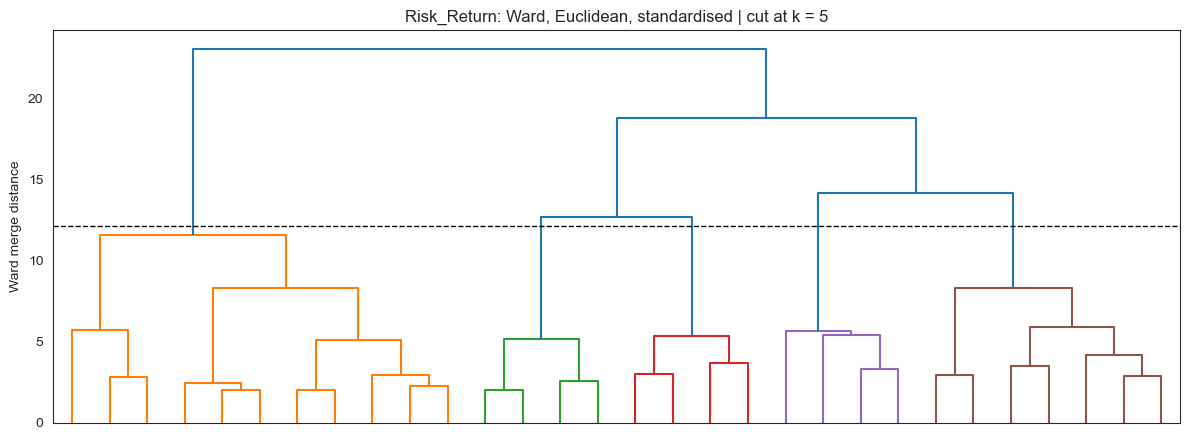

Risk_Return: cophenetic r = 0.479 | last 8 merge heights = [ 5.9  8.3  8.3 11.6 12.7 14.2 18.8 23.1]
=== Risk_Return, Ward, selected k = 5 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0055       1.2177   92  18.9
1                           0.0025       1.5139   48   9.9
2                           0.0017       0.9644  182  37.4
3                           0.0039       0.6663   98  20.2
4                           0.0011       0.4485   66  13.6


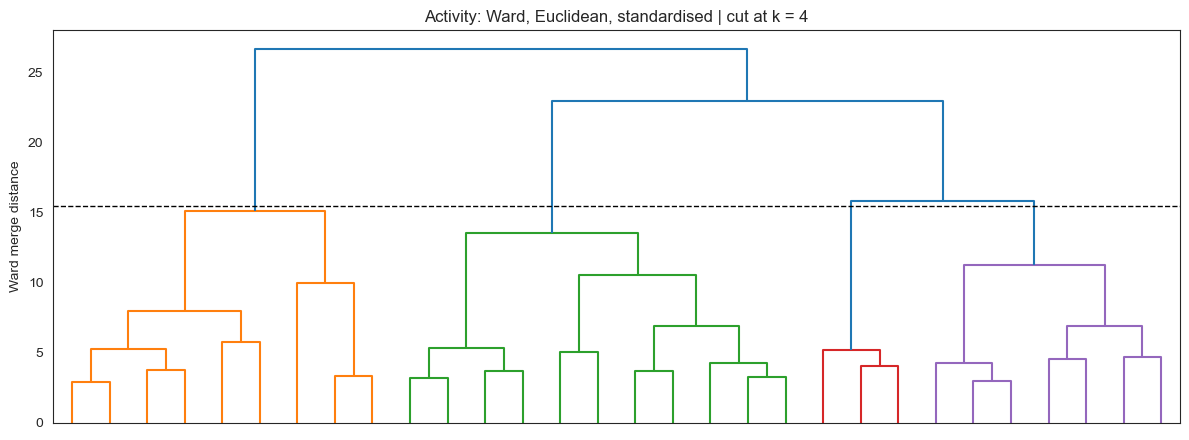

Activity: cophenetic r = 0.508 | last 8 merge heights = [10.  10.5 11.3 13.6 15.2 15.8 23.  26.7]
=== Activity, Ward, selected k = 4 ===
         Recency_median  Frequency_median  Monetary_median    n     %
Cluster                                                              
0                  54.5               2.0     1.784903e+10   82  16.9
1                  11.0               3.0     1.078527e+10  207  42.6
2                  11.0               3.0     3.969545e+10  154  31.7
3                  11.0               5.0     1.442997e+10   43   8.8


In [123]:
# ---------- SET THE WARD k after reading the table, and the profiles ----------
SELECTED_WARD = {"Risk_Return": 5, "Activity": 4}

# ---------- one Ward dendrogram per matrix, cut at the selected k (supporting evidence only) ----------
for name, X in matrices.items():
    k = SELECTED_WARD[name]
    Z = linkage(X.values, method="ward", metric="euclidean")
    cut = (Z[-k, 2] + Z[-(k - 1), 2]) / 2
    assert len(set(fcluster(Z, k, "maxclust"))) == k
    fig, ax = plt.subplots(figsize=(12, 4.5))
    dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=cut, ax=ax)
    ax.axhline(cut, color="black", ls="--", lw=1)
    ax.set_title(f"{name}: Ward, Euclidean, standardised | cut at k = {k}"); ax.set_ylabel("Ward merge distance")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/dendrogram_{name}.png", dpi=200); plt.show()
    c_, _ = cophenet(Z, pdist(X.values))
    print(f"{name}: cophenetic r = {c_:.3f} | last 8 merge heights = {np.round(Z[-8:, 2], 1)}")
    print(f"=== {name}, Ward, selected k = {k} ==="); print(profile(fit("Agglomerative", X, k), COLS[name]).to_string())

### K-Means

     Matrix Method  k  Inertia  Silhouette  Min_%                             Sizes  Inertia_drop_%  Feasible
Risk_Return KMeans  2  621.634       0.387   29.4                        [343, 143]             NaN      True
Risk_Return KMeans  3  461.179       0.329   24.5                   [202, 165, 119]            25.8      True
Risk_Return KMeans  4  371.571       0.326    8.4               [160, 153, 132, 41]            19.4      True
Risk_Return KMeans  5  309.960       0.338    5.8           [165, 124, 114, 55, 28]            16.6      True
Risk_Return KMeans  6  265.707       0.326    4.1        [134, 115, 85, 76, 56, 20]            14.3     False
Risk_Return KMeans  7  227.239       0.329    1.0     [126, 105, 84, 78, 47, 41, 5]            14.5     False
Risk_Return KMeans  8  194.249       0.354    1.0  [135, 80, 78, 76, 43, 40, 29, 5]            14.5     False
   Activity KMeans  2 1066.832       0.423   14.0                         [418, 68]             NaN      True
   Activit

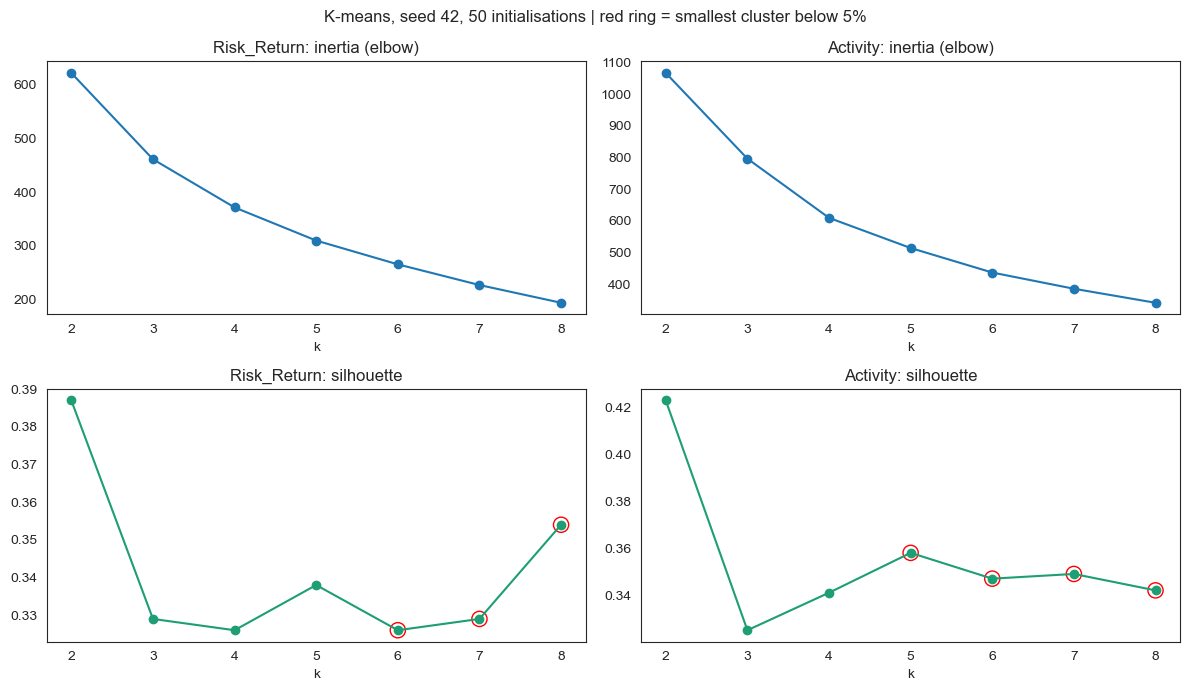


=== Risk_Return, K-means, k = 3 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0053       1.2214  119  24.5
1                           0.0026       0.6215  202  41.6
2                           0.0012       1.0805  165  34.0

=== Risk_Return, K-means, k = 4 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0043       0.9819  160  32.9
1                           0.0069       1.6772   41   8.4
2                           0.0011       1.1418  132  27.2
3                           0.0019       0.5746  153  31.5

=== Risk_Return, K-means, k = 5 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0042       0.9994  165  34.0
1                           0.0007       0.9777  114  23.5
2   

In [124]:
# ---------- K-means: compare k = 2..8 on silhouette, inertia and cluster sizes (seed and n_init fixed above) ----------
rows = []
for name, X in matrices.items():
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED, algorithm="elkan").fit(X); s_ = np.bincount(km.labels_)
        rows.append({"Matrix": name, "Method": "KMeans", "k": k, "Inertia": km.inertia_,
                     "Silhouette": round(silhouette_score(X, km.labels_), 3),
                     "Min_%": round(s_.min() / len(X) * 100, 1), "Sizes": sorted(s_.tolist(), reverse=True)})
km_comp = pd.DataFrame(rows)
km_comp["Inertia_drop_%"] = (km_comp.groupby("Matrix")["Inertia"].pct_change() * -100).round(1)   # gain from adding a cluster
km_comp["Feasible"] = km_comp["Min_%"] >= MIN_FRAC * 100
print(km_comp.round(3).to_string(index=False))
km_comp.to_csv(f"{OUT_DIR}/kmeans_k_comparison.csv", index=False)

# one combined table (Ward + K-means) used later in the notebook
comp = pd.concat([ward_comp, km_comp], ignore_index=True)
comp.to_csv(f"{OUT_DIR}/cluster_count_comparison.csv", index=False)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for j, name in enumerate(matrices):
    d_ = km_comp[km_comp.Matrix == name]
    ax[0, j].plot(d_["k"], d_["Inertia"], "o-"); ax[0, j].set_title(f"{name}: inertia (elbow)")
    ax[1, j].plot(d_["k"], d_["Silhouette"], "o-", color="#1D9E75"); ax[1, j].set_title(f"{name}: silhouette")
    bad = d_[~d_["Feasible"]]; ax[1, j].scatter(bad["k"], bad["Silhouette"], s=120, facecolors="none", edgecolors="red")
    for a_ in ax[:, j]: a_.set_xticks(range(2, 9)); a_.set_xlabel("k")
plt.suptitle(f"K-means, seed {SEED}, {N_INIT} initialisations | red ring = smallest cluster below 5%")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/kmeans_k_selection.png", dpi=200); plt.show()

# ---------- K-means: interpretable profiles of the candidate k (original units) ----------
for name, X in matrices.items():
    for k in [3, 4, 5]:
        print(f"\n=== {name}, K-means, k = {k} ==="); print(profile(fit("KMeans", X, k), COLS[name]).to_string())

In [125]:
# ---------- SET THE K-MEANS k after reading the table, the elbow and the profiles ----------
SELECTED_KM = {"Risk_Return": 3, "Activity": 4}

# ---------- reproducibility: seeds and initialisations ----------
for name, X in matrices.items():
    k = SELECTED_KM[name]
    base_lab = fit("KMeans", X, k, seed=SEED)
    aris = [adjusted_rand_score(base_lab, fit("KMeans", X, k, seed=s_)) for s_ in [1, 7, 99, 2024]]
    print(f"{name}, k = {k}: agreement with 4 other seeds (ARI) = {np.round(aris, 3)}")
    print(f"   inertia n_init=1: {KMeans(k, n_init=1, random_state=3, algorithm='elkan').fit(X).inertia_:.2f}"
          f" vs n_init={N_INIT}: {KMeans(k, n_init=N_INIT, random_state=SEED, algorithm='elkan').fit(X).inertia_:.2f}")
    print(f"=== {name}, K-means, selected k = {k} ==="); print(profile(base_lab, COLS[name]).to_string())

# ---------- final assignments for both algorithms (same shares) ----------
SELECTED = SELECTED_WARD                     # 2.5.2 repeats the selected WARD solution
final_labels = pd.DataFrame(index=all_feat.index)
for name, X in matrices.items():
    final_labels[f"{name}_KMeans"]        = fit("KMeans", X, SELECTED_KM[name])
    final_labels[f"{name}_Agglomerative"] = fit("Agglomerative", X, SELECTED_WARD[name])
final_labels.to_csv(f"{OUT_DIR}/final_cluster_labels.csv")

Risk_Return, k = 3: agreement with 4 other seeds (ARI) = [1. 1. 1. 1.]
   inertia n_init=1: 461.19 vs n_init=50: 461.18
=== Risk_Return, K-means, selected k = 3 ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0053       1.2214  119  24.5
1                           0.0026       0.6215  202  41.6
2                           0.0012       1.0805  165  34.0
Activity, k = 4: agreement with 4 other seeds (ARI) = [1. 1. 1. 1.]
   inertia n_init=1: 698.42 vs n_init=50: 609.83
=== Activity, K-means, selected k = 4 ===
         Recency_median  Frequency_median  Monetary_median    n     %
Cluster                                                              
0                  11.0               2.0     1.333641e+10  212  43.6
1                  11.0               4.0     1.282589e+10  122  25.1
2                  55.0               2.0     2.124212e+10   61  12.6
3                  11.0        

### 2.4 Cluster profiles and algorithm comparison


=== Risk_Return | KMeans | k = 3 (medians, original units) ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0053       1.2214  119  24.5
1                           0.0026       0.6215  202  41.6
2                           0.0012       1.0805  165  34.0

=== Risk_Return | Agglomerative | k = 5 (medians, original units) ===
         Mean_Weekly_Return_median  Beta_median    n     %
Cluster                                                   
0                           0.0055       1.2177   92  18.9
1                           0.0025       1.5139   48   9.9
2                           0.0017       0.9644  182  37.4
3                           0.0039       0.6663   98  20.2
4                           0.0011       0.4485   66  13.6

=== Activity | KMeans | k = 4 (medians, original units) ===
         Recency_median  Frequency_median  Monetary_median    n     %
Cluster                   

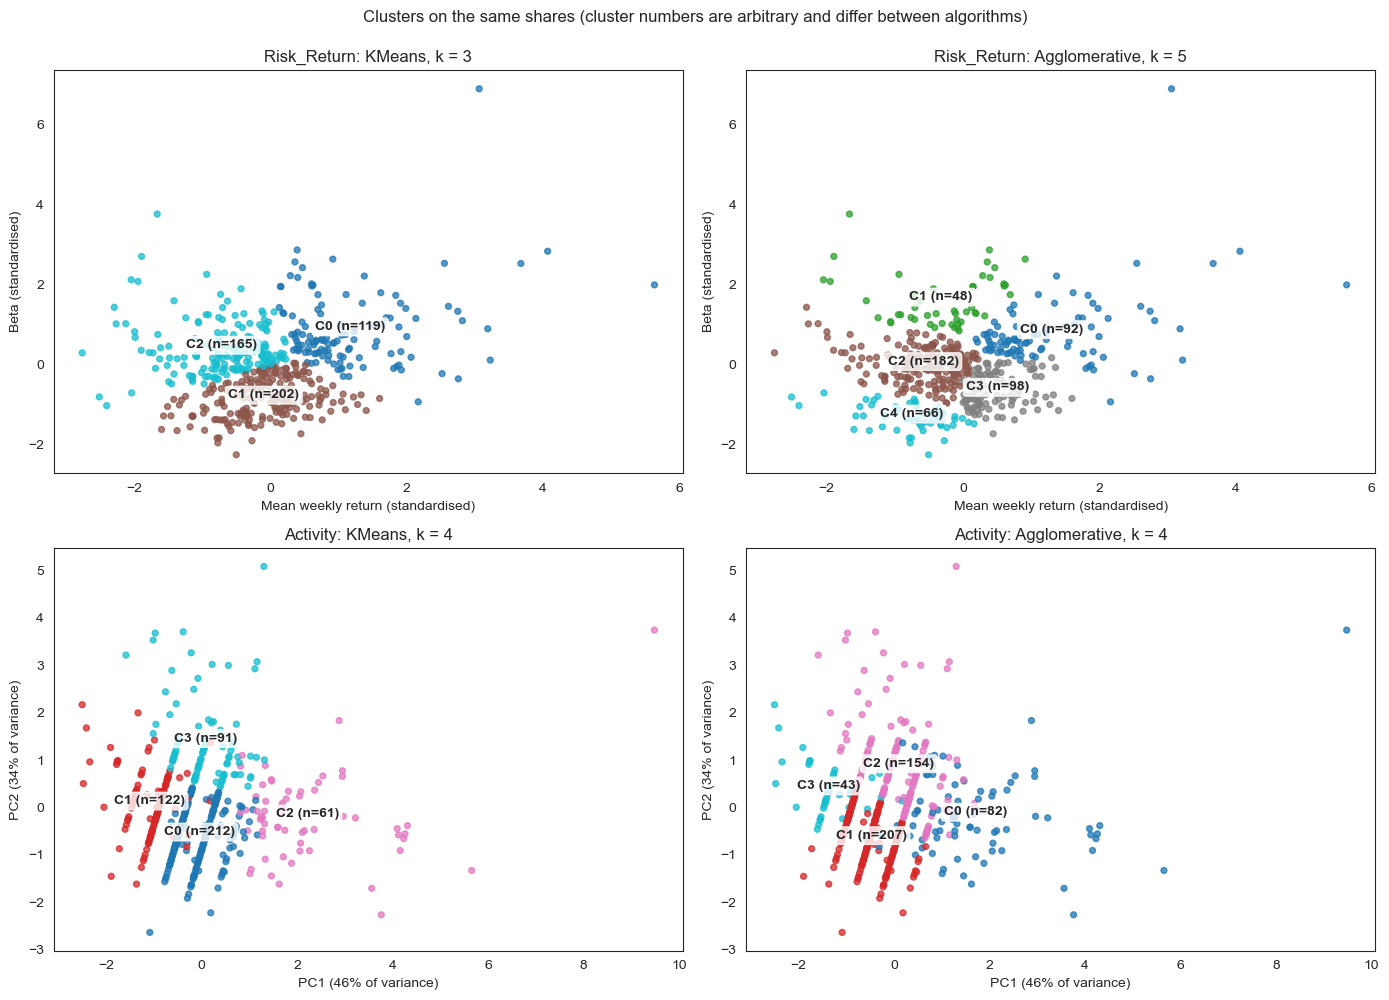


Risk_Return: cross-tabulation, shares = 486
Ward     0   1    2   3   4
KMeans                     
0       90  16    0  13   0
1        0   0   54  85  63
2        2  32  128   0   3

Activity: cross-tabulation, shares = 486
Ward     0    1   2   3
KMeans                 
0       14  146  52   0
1        4   61  14  43
2       57    0   4   0
3        7    0  84   0

     Matrix  k_KMeans  k_Ward  Shares   ARI  Matched_agreement_%  Silhouette_KMeans  Silhouette_Ward  DaviesBouldin_KMeans  DaviesBouldin_Ward
Risk_Return         3       5     486 0.396                 62.3              0.329            0.304                 1.010               0.938
   Activity         4       4     486 0.343                 67.9              0.341            0.289                 0.937               1.022


In [126]:
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score, adjusted_rand_score
from scipy.optimize import linear_sum_assignment

K_USED = {"KMeans": SELECTED_KM, "Agglomerative": SELECTED_WARD}      # each method's own selected k

# ---- profiles in ORIGINAL units for both algorithms ----
for name in matrices:
    for method in ["KMeans", "Agglomerative"]:
        kk = K_USED[method][name]
        print(f"\n=== {name} | {method} | k = {kk} (medians, original units) ===")
        print(profile(final_labels[f"{name}_{method}"].values, COLS[name]).to_string())

# ---- labelled 2D visualisation ----
# Risk/return has only two features, so it is plotted directly (no reduction).
# Activity has three, so PCA projects the standardised data to 2D; the axes show the variance each component keeps.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for r_, (name, X) in enumerate(matrices.items()):
    if name == "Risk_Return":
        xy = X.values
        xl, yl = "Mean weekly return (standardised)", "Beta (standardised)"
    else:
        p2 = PCA(n_components=2).fit(X)
        xy = p2.transform(X)
        ev = p2.explained_variance_ratio_
        xl, yl = f"PC1 ({ev[0] * 100:.0f}% of variance)", f"PC2 ({ev[1] * 100:.0f}% of variance)"
        print("\nPCA loadings (activity):")
        print(pd.DataFrame(p2.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(3))
        print(f"2D projection keeps {ev.sum() * 100:.0f}% of the variance; distances in the plot are approximate.")

    for c_, method in enumerate(["KMeans", "Agglomerative"]):
        lab = final_labels[f"{name}_{method}"].values
        ax = axes[r_, c_]
        ax.scatter(xy[:, 0], xy[:, 1], c=lab, cmap="tab10", s=18, alpha=0.75)
        for k_ in np.unique(lab):
            m_ = lab == k_
            ax.annotate(f"C{k_} (n={m_.sum()})", xy[m_].mean(axis=0), ha="center", fontsize=10, fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
        ax.set_title(f"{name}: {method}, k = {K_USED[method][name]}")
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)

plt.suptitle("Clusters on the same shares (cluster numbers are arbitrary and differ between algorithms)", y=0.995)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/cluster_scatter_2d.png", dpi=200)
plt.show()

# ---- algorithm comparison on the SAME shares ----
rows = []
for name, X in matrices.items():
    a_ = final_labels[f"{name}_KMeans"]
    b_ = final_labels[f"{name}_Agglomerative"]
    ct = pd.crosstab(a_, b_, rownames=["KMeans"], colnames=["Ward"])
    ri, ci = linear_sum_assignment(-ct.values)                  # best label matching (cluster numbers are arbitrary)
    print(f"\n{name}: cross-tabulation, shares = {len(a_)}")
    print(ct)
    rows.append({
        "Matrix": name,
        "k_KMeans": SELECTED_KM[name], "k_Ward": SELECTED_WARD[name],
        "Shares": len(a_),
        "ARI": round(adjusted_rand_score(a_, b_), 3),
        "Matched_agreement_%": round(ct.values[ri, ci].sum() / ct.values.sum() * 100, 1),
        "Silhouette_KMeans": round(silhouette_score(X, a_), 3),
        "Silhouette_Ward": round(silhouette_score(X, b_), 3),
        "DaviesBouldin_KMeans": round(davies_bouldin_score(X, a_), 3),
        "DaviesBouldin_Ward": round(davies_bouldin_score(X, b_), 3),
    })

algo_cmp = pd.DataFrame(rows)
print()
print(algo_cmp.to_string(index=False))
algo_cmp.to_csv(f"{OUT_DIR}/algorithm_comparison.csv", index=False)

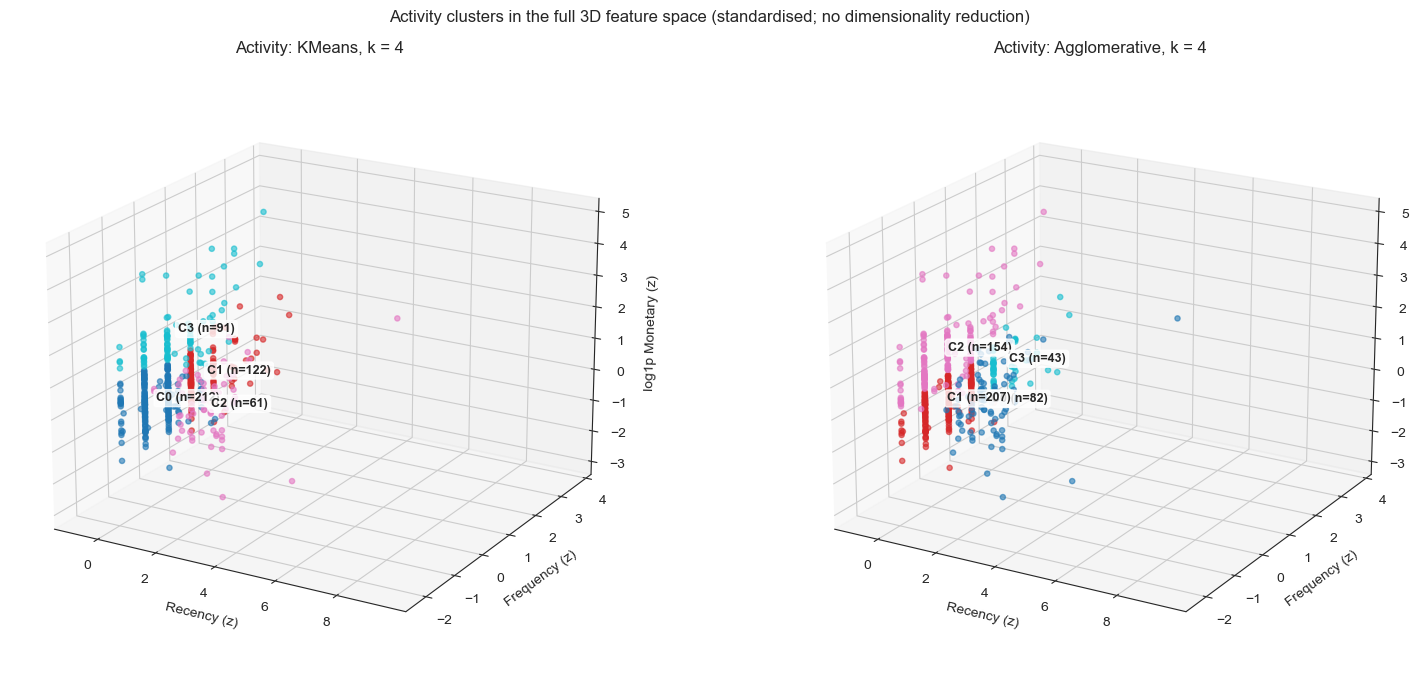

In [127]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3D projection)

X = matrices["Activity"]                                   # standardised Recency, Frequency, log1p_Monetary
cols = list(X.columns)
fig = plt.figure(figsize=(16, 7))
for i, method in enumerate(["KMeans", "Agglomerative"]):
    lab = final_labels[f"Activity_{method}"].values
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.scatter(X[cols[0]], X[cols[1]], X[cols[2]], c=lab, cmap="tab10", s=14, alpha=0.6, depthshade=False)
    for k_ in np.unique(lab):                              # label each cluster at its centre
        m_ = lab == k_
        cx, cy, cz = X.values[m_].mean(axis=0)
        ax.text(cx, cy, cz, f"C{k_} (n={m_.sum()})", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
    ax.set_xlabel("Recency (z)"); ax.set_ylabel("Frequency (z)"); ax.set_zlabel("log1p Monetary (z)")
    ax.set_title(f"Activity: {method}, k = {K_USED[method]['Activity']}")
    ax.view_init(elev=20, azim=-60)                        # change these angles if clusters are hidden
fig.suptitle("Activity clusters in the full 3D feature space (standardised; no dimensionality reduction)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/activity_3d.png", dpi=200); plt.show()

### 2.5.1 Correlation analysis among R, F and log1p(M)

PEARSON
                 Recency  Frequency  log1p_Monetary
Recency           1.000     -0.346           0.152
Frequency        -0.346      1.000           0.013
log1p_Monetary    0.152      0.013           1.000 

SPEARMAN
                 Recency  Frequency  log1p_Monetary
Recency           1.000     -0.196           0.137
Frequency        -0.196      1.000          -0.048
log1p_Monetary    0.137     -0.048           1.000


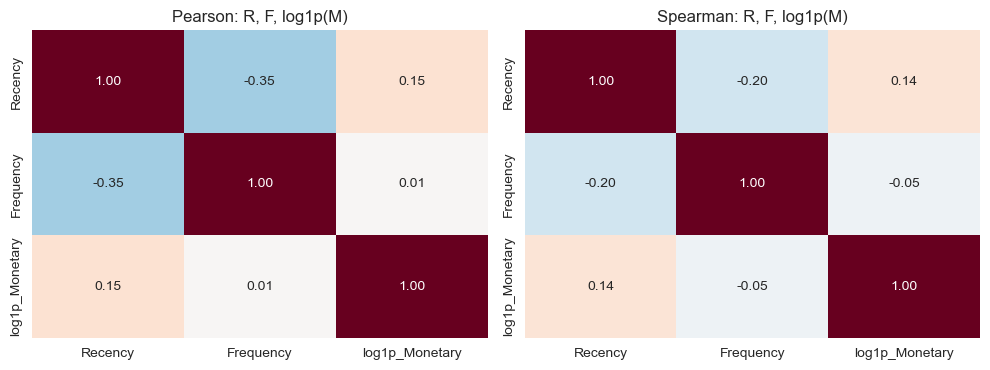


Share of total variance by principal component: [0.458 0.336 0.206]
Loadings on PC1:
 Recency           0.711
Frequency        -0.650
log1p_Monetary    0.268
dtype: float64

VIF (above about 5 suggests strong overlap): {'Recency': 1.17, 'Frequency': 1.14, 'log1p_Monetary': 1.03}

Correlation of risk/return features with activity features:
                     Recency  Frequency  log1p_Monetary
Mean_Weekly_Return    0.076      0.001           0.278
Beta                  0.069      0.083           0.240


In [128]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

act = all_feat[['Recency', 'Frequency', 'Monetary']].copy()
act['log1p_Monetary'] = np.log1p(act['Monetary'])
act = act[['Recency', 'Frequency', 'log1p_Monetary']]

# 1. Correlations
pearson  = act.corr(method='pearson')
spearman = act.corr(method='spearman')
print('PEARSON\n', pearson.round(3), '\n\nSPEARMAN\n', spearman.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, c, t in zip(ax, [pearson, spearman], ['Pearson', 'Spearman']):
    sns.heatmap(c, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=a, cbar=False)
    a.set_title(f'{t}: R, F, log1p(M)')
plt.tight_layout(); plt.savefig('outputs/rfm_correlations.png', dpi=200); plt.show()

# 2. Shared information after standardisation: PCA variance split
Z = (act - act.mean()) / act.std()
pca = PCA().fit(Z)
print('\nShare of total variance by principal component:', np.round(pca.explained_variance_ratio_, 3))
print('Loadings on PC1:\n', pd.Series(pca.components_[0], index=act.columns).round(3))

# 3. Variance inflation factor (how much of each feature the other two explain)
vif = {c: 1 / (1 - (act.drop(columns=c).apply(lambda s: s).pipe(
          lambda X: np.corrcoef(np.c_[X.values, act[c].values].T)[-1, :-1] @
                    np.linalg.solve(np.corrcoef(X.values.T), np.corrcoef(np.c_[X.values, act[c].values].T)[-1, :-1]))))
       for c in act.columns}
print('\nVIF (above about 5 suggests strong overlap):', {k: round(v, 2) for k, v in vif.items()})

# 4. Cross-block check: do activity features overlap with risk and return?
cross = all_feat[['Mean_Weekly_Return', 'Beta']].join(act).corr().loc[['Mean_Weekly_Return', 'Beta'], act.columns]
print('\nCorrelation of risk/return features with activity features:\n', cross.round(3))

### 2.5.2 Removal of Monetary (Ward, R and F only)

Shares: 486 | k = 4
Adjusted Rand index (R,F,M vs R,F only): 0.203
Silhouette: full = 0.289 | R,F only = 0.516

Cross-tabulation (rows = full RFM, columns = R,F only):
RF_only     0   1   2   3
Full_RFM                 
0           3  69   0  10
1         141   0  66   0
2          86   9  59   0
3          42   1   0   0

=== Full solution: R, F, log1p(M) ===
           n  R_median  F_median  M_median_USD_bn  M_IQR_USD_bn
Cluster                                                        
0         82      54.5       2.0            17.85         19.48
1        207      11.0       3.0            10.79          7.04
2        154      11.0       3.0            39.70         40.17
3         43      11.0       5.0            14.43          9.33

=== Reduced solution: R, F only ===
           n  R_median  F_median  M_median_USD_bn  M_IQR_USD_bn
Cluster                                                        
0        272      11.0       4.0            14.86         20.74
1         79      49.0  

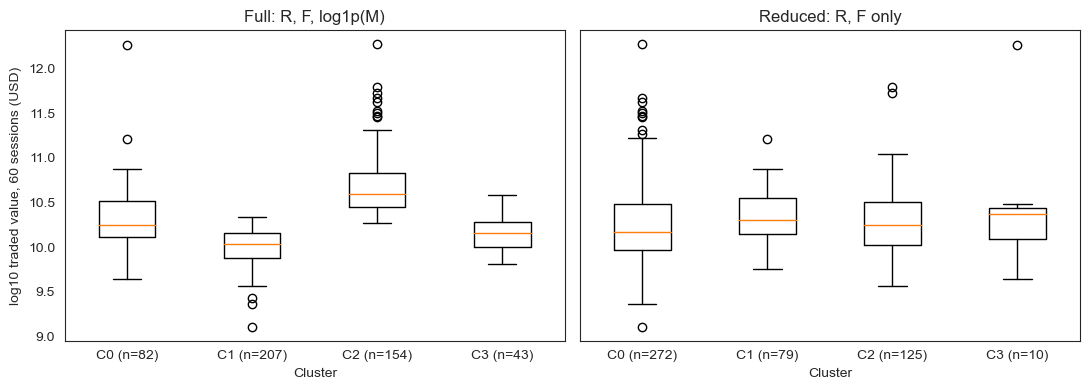

In [129]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score

K = SELECTED_WARD['Activity']                               # the selected Ward cluster count for the RFM matrix
idx = X_act.index                                       # same shares as the full RFM solution

# 1. Full solution: R, F, log1p(M), already standardised (X_act)
lab_full = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X_act)

# 2. Reduced solution: R and F only, standardised afresh
rf = all_feat.loc[idx, ['Recency', 'Frequency']]
X_rf = pd.DataFrame(StandardScaler().fit_transform(rf), index=idx, columns=rf.columns)
lab_rf = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X_rf)

# 3. Compare memberships
ari = adjusted_rand_score(lab_full, lab_rf)
print(f'Shares: {len(idx)} | k = {K}')
print(f'Adjusted Rand index (R,F,M vs R,F only): {ari:.3f}')
print(f'Silhouette: full = {silhouette_score(X_act, lab_full):.3f} | R,F only = {silhouette_score(X_rf, lab_rf):.3f}')
print('\nCross-tabulation (rows = full RFM, columns = R,F only):')
print(pd.crosstab(pd.Series(lab_full, index=idx, name='Full_RFM'), pd.Series(lab_rf, index=idx, name='RF_only')))

# 4. Traded value profiles of both solutions (original units)
d = all_feat.loc[idx, ['Recency', 'Frequency', 'Monetary']].copy()
d['log1p_M'] = np.log1p(d['Monetary'])

def prof(labels, name):
    g = d.assign(Cluster=labels).groupby('Cluster')
    out = pd.DataFrame({'n': g.size(),
                        'R_median': g['Recency'].median(),
                        'F_median': g['Frequency'].median(),
                        'M_median_USD_bn': (g['Monetary'].median() / 1e9).round(2),
                        'M_IQR_USD_bn': ((g['Monetary'].quantile(.75) - g['Monetary'].quantile(.25)) / 1e9).round(2)})
    print(f'\n=== {name} ==='); print(out.round(2).to_string())
    return out

p_full = prof(lab_full, 'Full solution: R, F, log1p(M)')
p_rf   = prof(lab_rf,   'Reduced solution: R, F only')

# 5. How much of the variation in traded value does each solution explain? (between-cluster share of variance)
def eta_sq(labels, col):
    s = d[col]; tot = ((s - s.mean()) ** 2).sum()
    betw = sum(len(g) * (g.mean() - s.mean()) ** 2 for _, g in s.groupby(labels))
    return betw / tot

for col in ['log1p_M', 'Recency', 'Frequency']:
    print(f'{col:10s} variance explained by clusters: full = {eta_sq(lab_full, col):.2f} | R,F only = {eta_sq(lab_rf, col):.2f}')

# 6. Plot: log10 traded value by cluster for both solutions
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, labs, t in zip(ax, [lab_full, lab_rf], ['Full: R, F, log1p(M)', 'Reduced: R, F only']):
    data = [np.log10(d.loc[labs == c, 'Monetary']) for c in range(K)]
    a.boxplot(data, labels=[f'C{c} (n={len(x)})' for c, x in enumerate(data)])
    a.set_title(t); a.set_xlabel('Cluster')
ax[0].set_ylabel('log10 traded value, 60 sessions (USD)')
plt.tight_layout(); plt.savefig('outputs/removal_of_monetary.png', dpi=200); plt.show()

Shares: 486 | k = 4
Adjusted Rand index = 0.20  (1 = identical memberships, 0 = no better than chance)
Shares sitting in the matched cluster: 55%  (217 shares change cluster)

FULL solution (R, F, log1p M), clusters ranked by traded value
       n  R_median_days  F_median  M_median_USD_bn  M_IQR_USD_bn  % kept in matched cluster
L1  207           11.0       3.0            10.79          7.04                         68
L2   43           11.0       5.0            14.43          9.33                          0
L3   82           54.5       2.0            17.85         19.48                         84
L4  154           11.0       3.0            39.70         40.17                         38

REDUCED solution (R, F only), clusters matched to the full ones
             n  R_median_days  F_median  M_median_USD_bn  M_IQR_USD_bn
L1 match  272           11.0       4.0            14.86         20.74
L2 match   10          102.0       0.0            23.79         15.15
L3 match   79           49.0 

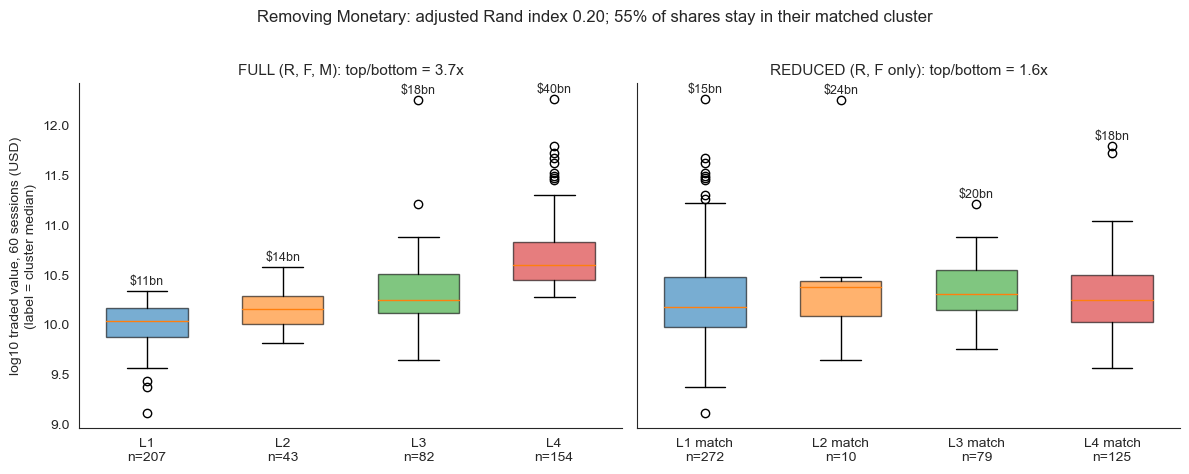

In [130]:
# ================= 2.5.2 Removal of Monetary: Ward RFM solution repeated with R and F only =================
from scipy.optimize import linear_sum_assignment

K_ACT = SELECTED_WARD["Activity"]                    # same selected cluster count
idx = X_act.index                                    # same shares as the full RFM solution

lab_full = fit("Agglomerative", X_act, K_ACT)        # R, F, log1p(M)  (already standardised)
rf = all_feat.loc[idx, ["Recency", "Frequency"]]
X_rf = pd.DataFrame(StandardScaler().fit_transform(rf), index=idx, columns=rf.columns)   # reduced matrix standardised AFRESH
lab_rf = fit("Agglomerative", X_rf, K_ACT)           # R, F only

d = all_feat.loc[idx, ["Recency", "Frequency", "Monetary"]].copy()
d["log1p_M"] = np.log1p(d["Monetary"]); d["M_bn"] = d["Monetary"] / 1e9

# ---- 1. compare memberships: adjusted Rand index (ignores cluster numbering) ----
ari = adjusted_rand_score(lab_full, lab_rf)
ct = pd.crosstab(pd.Series(lab_full, index=idx), pd.Series(lab_rf, index=idx))
ri, ci = linear_sum_assignment(-ct.values)                         # pair each full cluster with its closest reduced cluster
match = dict(zip(ct.index[ri], ct.columns[ci]))
agree = ct.values[ri, ci].sum() / ct.values.sum() * 100
print(f"Shares: {len(idx)} | k = {K_ACT}")
print(f"Adjusted Rand index = {ari:.2f}  (1 = identical memberships, 0 = no better than chance)")
print(f"Shares sitting in the matched cluster: {agree:.0f}%  ({int((1 - agree / 100) * len(idx))} shares change cluster)")

# ---- 2. name the full clusters by traded value: L1 = lowest median traded value ... L4 = highest ----
med_full = d.groupby(lab_full)["M_bn"].median().sort_values()
order_full = list(med_full.index)
nm = {c: f"L{i + 1}" for i, c in enumerate(order_full)}
order_rf = [match[c] for c in order_full]                          # reduced clusters in the matched order

def cluster_table(labels, order, names):
    g = d.groupby(labels)
    t = pd.DataFrame({"n": g.size(), "R_median_days": g["Recency"].median(), "F_median": g["Frequency"].median(),
                      "M_median_USD_bn": g["M_bn"].median(), "M_IQR_USD_bn": g["M_bn"].quantile(.75) - g["M_bn"].quantile(.25)}).loc[order]
    t.index = names; return t.round(2)

tab_full = cluster_table(lab_full, order_full, [nm[c] for c in order_full])
tab_full["% kept in matched cluster"] = [round(ct.loc[c, match[c]] / ct.loc[c].sum() * 100) for c in order_full]
tab_rf = cluster_table(lab_rf, order_rf, [f"{nm[c]} match" for c in order_full])
print("\nFULL solution (R, F, log1p M), clusters ranked by traded value\n", tab_full.to_string())
print("\nREDUCED solution (R, F only), clusters matched to the full ones\n", tab_rf.to_string())

# ---- 3. does the reduced solution still separate traded value? ----
def eta_sq(labels, col):                                           # share of a feature's variance explained by the clusters
    s_ = d[col]; tot = ((s_ - s_.mean()) ** 2).sum()
    return sum(len(g) * (g.mean() - s_.mean()) ** 2 for _, g in s_.groupby(labels)) / tot
e = pd.DataFrame({"Full (R,F,M)": [eta_sq(lab_full, c) for c in ["log1p_M", "Recency", "Frequency"]],
                  "Reduced (R,F)": [eta_sq(lab_rf, c) for c in ["log1p_M", "Recency", "Frequency"]]},
                 index=["Traded value", "Recency", "Frequency"]).round(2)
print("\nShare of each feature's variance explained by the clusters\n", e.to_string())

med_rf = d.groupby(lab_rf)["M_bn"].median()
ratio_full, ratio_rf = med_full.iloc[-1] / med_full.iloc[0], med_rf.max() / med_rf.min()
drop = e.loc["Traded value", "Full (R,F,M)"] - e.loc["Traded value", "Reduced (R,F)"]
print(f"\nHighest / lowest cluster median traded value: full = {ratio_full:.1f}x, reduced = {ratio_rf:.1f}x")
if drop >= 0.30:
    verdict = "LIQUIDITY: without M the clusters stop separating traded value, so M mainly separates liquidity levels."
elif drop <= 0.10:
    verdict = "ACTIVITY: the clusters still separate traded value without M, so M mainly repeats what R and F capture."
else:
    verdict = "MIXED: M separates some liquidity levels, but part of the traded-value pattern comes from R and F."
print("VERDICT (rule: explained-variance drop >= 0.30 = liquidity, <= 0.10 = activity):", verdict)

# ---- 4. one picture: traded value in each cluster, same colours for matched clusters ----
PAL = plt.cm.tab10(np.arange(K_ACT))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for a_, labs, order, names, ttl in [(ax[0], lab_full, order_full, [nm[c] for c in order_full], f"FULL (R, F, M): top/bottom = {ratio_full:.1f}x"),
                                    (ax[1], lab_rf, order_rf, [f"{nm[c]} match" for c in order_full], f"REDUCED (R, F only): top/bottom = {ratio_rf:.1f}x")]:
    data = [np.log10(d.loc[labs == c, "Monetary"]) for c in order]
    b = a_.boxplot(data, patch_artist=True, widths=0.6)
    for p_, col_ in zip(b["boxes"], PAL): p_.set_facecolor(col_); p_.set_alpha(0.6)
    for i_, (c, x) in enumerate(zip(order, data)):
        a_.text(i_ + 1, x.max() + 0.06, f"${d.loc[labs == c, 'M_bn'].median():.0f}bn", ha="center", fontsize=9)
    a_.set_xticklabels([f"{n_}\nn={len(x)}" for n_, x in zip(names, data)]); a_.set_title(ttl, fontsize=11)
    for s_ in ("top", "right"): a_.spines[s_].set_visible(False)
ax[0].set_ylabel("log10 traded value, 60 sessions (USD)\n(label = cluster median)")
fig.suptitle(f"Removing Monetary: adjusted Rand index {ari:.2f}; {agree:.0f}% of shares stay in their matched cluster", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/removal_of_monetary.png", dpi=200, bbox_inches="tight"); plt.show()
# Traded value is only a liquidity proxy: spread and price impact are not measured here.

## 3.2 Review of results and visualisation

### Visualisations for 3.2.1 (profiles, sector composition, overlap)

Shares without a sector: 0

Risk and return clusters (KMeans), medians in original units
                    Mean_Weekly_Return    Beta    n     %
Risk_Return_KMeans                                       
0                               0.0053  1.2214  119  24.5
1                               0.0026  0.6215  202  41.6
2                               0.0012  1.0805  165  34.0

Trading activity clusters (KMeans), medians in original units
                 Recency  Frequency  Monetary_USD_bn    n     %
Activity_KMeans                                                
0                   11.0        2.0          13.3364  212  43.6
1                   11.0        4.0          12.8259  122  25.1
2                   55.0        2.0          21.2421   61  12.6
3                   11.0        3.0          60.1834   91  18.7


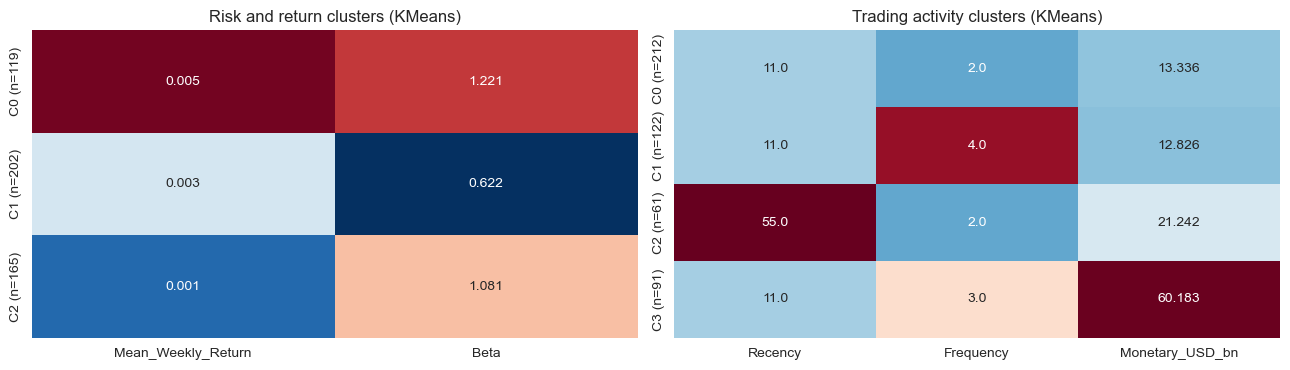

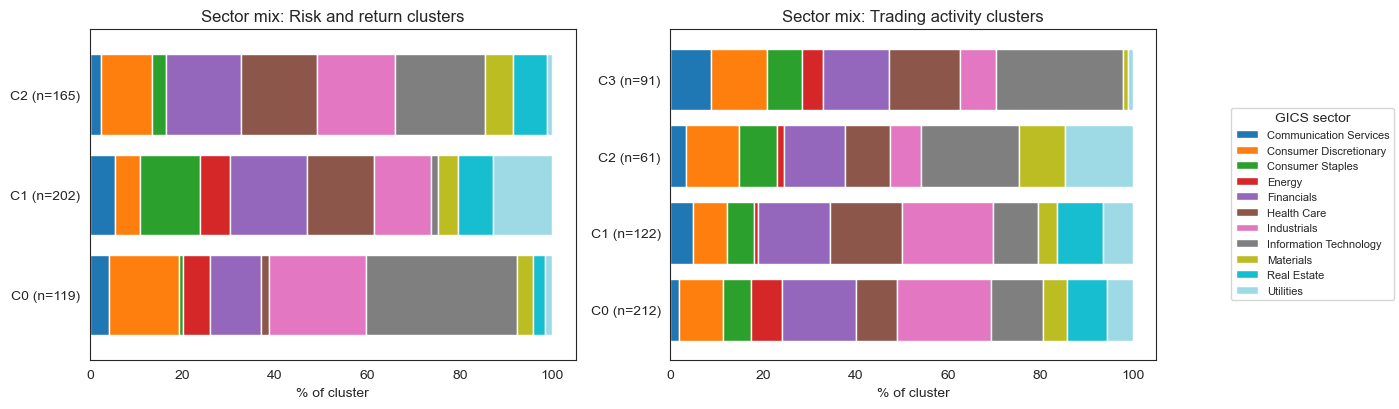

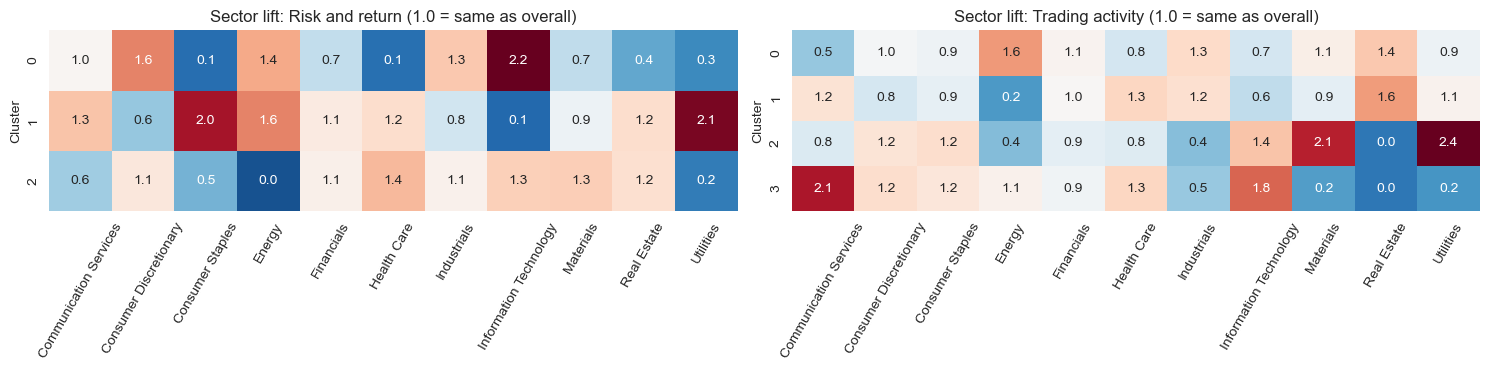

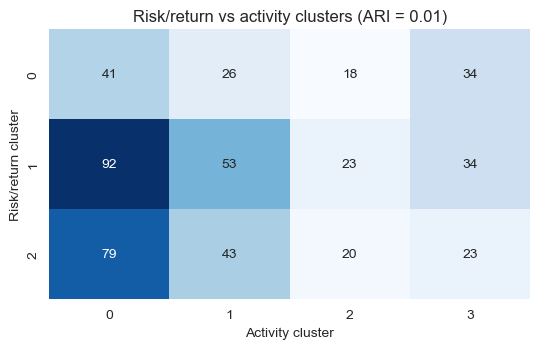

In [131]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import adjusted_rand_score

METHOD = "KMeans"                                   # or "Agglomerative"; use the same method in the text
rr, ac = f"Risk_Return_{METHOD}", f"Activity_{METHOD}"

# ---------- sector lookup (current GICS sector from the Wikipedia table) ----------
sector = (sp500_df.assign(Share=sp500_df["Symbol"].str.replace(".", "-", regex=False))
          .set_index("Share")["GICS Sector"].rename("Sector"))
prof = all_feat.join(final_labels).join(sector)
print("Shares without a sector:", int(prof["Sector"].isna().sum()))

# ---------- 1. profiles in ORIGINAL units ----------
rr_prof = prof.groupby(rr)[["Mean_Weekly_Return", "Beta"]].median()
ac_prof = prof.groupby(ac)[["Recency", "Frequency", "Monetary"]].median()
ac_prof["Monetary"] = ac_prof["Monetary"] / 1e9                    # USD billions
ac_prof = ac_prof.rename(columns={"Monetary": "Monetary_USD_bn"})
for t_, p_, c_ in [("Risk and return", rr_prof, rr), ("Trading activity", ac_prof, ac)]:
    p_["n"] = prof.groupby(c_).size(); p_["%"] = (p_["n"] / len(prof) * 100).round(1)
    print(f"\n{t_} clusters ({METHOD}), medians in original units"); print(p_.round(4).to_string())

# ---------- Figure 1: profile heatmaps (colour = z-score of cluster median, numbers = original units) ----------
def prof_heat(ax, tbl, title):
    vals = tbl.drop(columns=["n", "%"]); z = (vals - vals.mean()) / vals.std(ddof=0)
    z.index = [f"C{i} (n={tbl.loc[i, 'n']})" for i in tbl.index]
    sns.heatmap(z, annot=vals.round(3).astype(str).values, fmt="", cmap="RdBu_r", center=0, cbar=False, ax=ax)
    ax.set_title(title); ax.set_ylabel("")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
prof_heat(ax[0], rr_prof, f"Risk and return clusters ({METHOD})"); prof_heat(ax[1], ac_prof, f"Trading activity clusters ({METHOD})")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_cluster_profiles.png", dpi=200); plt.show()

# ---------- Figure 2: sector composition of each cluster (100% stacked bars) ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for a, col, t_ in zip(ax, [rr, ac], ["Risk and return clusters", "Trading activity clusters"]):
    ct = pd.crosstab(prof[col], prof["Sector"], normalize="index") * 100
    ct.index = [f"C{i} (n={(prof[col] == i).sum()})" for i in ct.index]
    ct.plot(kind="barh", stacked=True, ax=a, colormap="tab20", legend=False, width=0.8)
    a.set_title(f"Sector mix: {t_}"); a.set_xlabel("% of cluster")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="center right", fontsize=8, title="GICS sector")
plt.tight_layout(rect=[0, 0, 0.84, 1]); plt.savefig(f"{OUT_DIR}/fig2_sector_composition.png", dpi=200); plt.show()

# ---------- Figure 3: over/under-representation vs the whole sample (lift; 1.0 = same as overall mix) ----------
overall = prof["Sector"].value_counts(normalize=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for a, col, t_ in zip(ax, [rr, ac], ["Risk and return", "Trading activity"]):
    lift = pd.crosstab(prof[col], prof["Sector"], normalize="index").div(overall, axis=1)
    sns.heatmap(lift, annot=True, fmt=".1f", cmap="RdBu_r", center=1, cbar=False, ax=a)
    a.set_title(f"Sector lift: {t_} (1.0 = same as overall)"); a.set_ylabel("Cluster"); a.set_xlabel("")
    a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_sector_lift.png", dpi=200); plt.show()

# ---------- Figure 4: do the two clusterings overlap? ----------
ct = pd.crosstab(prof[rr].rename("Risk/return cluster"), prof[ac].rename("Activity cluster"))
plt.figure(figsize=(5.5, 3.6)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Risk/return vs activity clusters (ARI = {adjusted_rand_score(prof[rr], prof[ac]):.2f})")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_cluster_overlap.png", dpi=200); plt.show()

prof.to_csv(f"{OUT_DIR}/share_features_clusters_sectors.csv")
# Sensitivity figures already saved earlier: rfm_correlations.png and removal_of_monetary.png

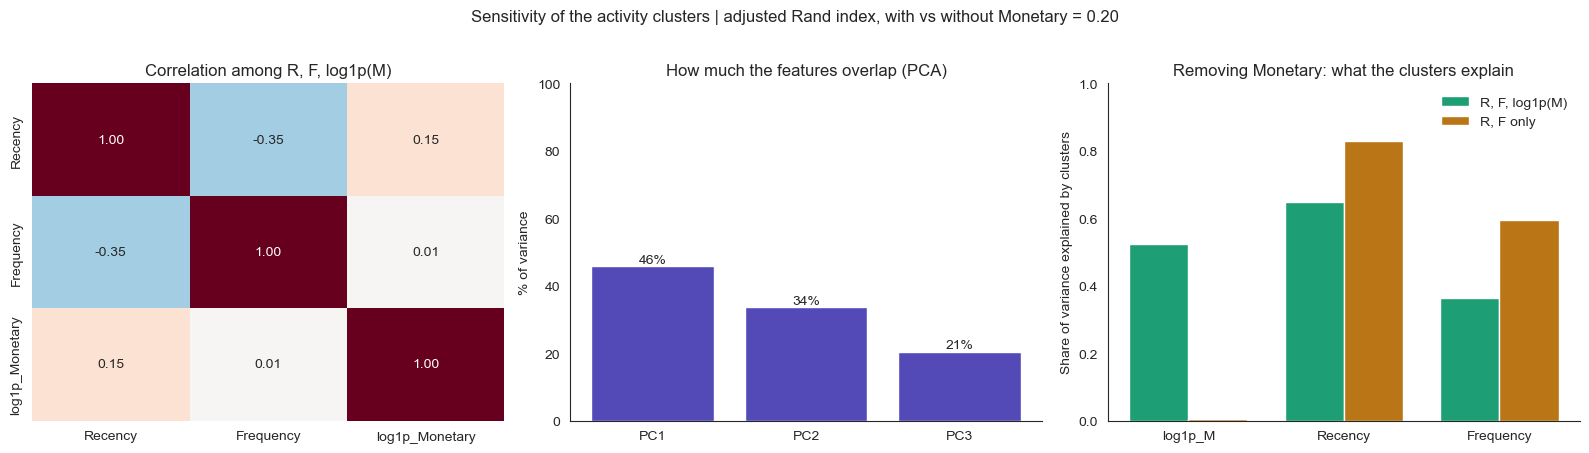

In [132]:
# ---------- one summary figure for 3.2.2: correlations, overlap, and what removing Monetary does ----------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

sns.heatmap(pearson, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, cbar=False, ax=ax[0])
ax[0].set_title("Correlation among R, F, log1p(M)")

ev = pca.explained_variance_ratio_ * 100
ax[1].bar([f"PC{i + 1}" for i in range(len(ev))], ev, color="#534AB7")
for i_, v_ in enumerate(ev): ax[1].text(i_, v_ + 1, f"{v_:.0f}%", ha="center", fontsize=10)
ax[1].set_ylim(0, 100); ax[1].set_ylabel("% of variance"); ax[1].set_title("How much the features overlap (PCA)")

cols_ = ["log1p_M", "Recency", "Frequency"]; x_ = np.arange(len(cols_)); w_ = 0.38
full_ = [eta_sq(lab_full, c_) for c_ in cols_]; rf_ = [eta_sq(lab_rf, c_) for c_ in cols_]
ax[2].bar(x_ - w_ / 2, full_, w_, label="R, F, log1p(M)", color="#1D9E75")
ax[2].bar(x_ + w_ / 2, rf_, w_, label="R, F only", color="#BA7517")
ax[2].set_xticks(x_); ax[2].set_xticklabels(cols_); ax[2].set_ylim(0, 1); ax[2].legend(frameon=False)
ax[2].set_ylabel("Share of variance explained by clusters"); ax[2].set_title("Removing Monetary: what the clusters explain")

for a_ in ax[1:]:
    for s_ in ("top", "right"): a_.spines[s_].set_visible(False)
fig.suptitle(f"Sensitivity of the activity clusters | adjusted Rand index, with vs without Monetary = {adjusted_rand_score(lab_full, lab_rf):.2f}", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sensitivity_summary.png", dpi=200, bbox_inches="tight"); plt.show()